# Estimativa de Bandas SWIR — Treinamento de Modelos (mosaicos sazonais secos A × B)

Regressão espectral: **B04–B09 (SWIR)** a partir de **VNIR (B01, B02, B3N) + TIR (B10–B14)**.
Mesmo roteiro do `train_swir_models.ipynb` (zero-cloud), com os mosaicos de
`building_dataset/build_mosaico_sazonal_seco.py` (estação seca, jun–out, qualityMosaic v5):

- **A** — 2000-03 a 2008-03: VNIR + SWIR + TIR (SWIR medido)
- **B** — 2009–2020: VNIR + TIR (SWIR a estimar)

| Modelo | Método | Hiperparâmetros |
|---|---|---|
| **PLS** | Partial Least Squares | `n_components` otimizado por CV |
| **XGBoost** | Gradient Boosting | `RandomizedSearchCV` + `KFold` |
| **RF** | Random Forest (equivalente ao `ee.Classifier.smileRandomForest`) | `RandomizedSearchCV` + `KFold` |

> **Fonte:** `SUFIXO_FONTE` na célula 2 — `'_hm_razao'` (padrão, mosaicos harmonizados contra o
> Landsat) ou `''` (original). Entrada e saídas levam o sufixo.
>
> **Entrada:** `src/Dados/ASTER_Samples_sazonal_seco<SUFIXO>/` (gerados por
> `building_dataset/pontos_sazonal_seco_pareados.py`: etapa 1, etapa 2 e baixar)
> - `points_sazonal_seco_A.csv` — treino/teste: VNIR + SWIR + TIR + `n_obs` do mosaico A
> - `points_sazonal_seco_pareados.csv` — os mesmos pontos com o B (sufixos `_A` / `_B`)
>
> **Saídas:** `models/sazonal_seco<SUFIXO>/`

**Diferenças do notebook zero-cloud.** O mosaico sazonal não tem banda `data` (cada pixel vem do
qualityMosaic de várias cenas da seca), então saem os testes por cena e por mês (9.1 mesma
estação, 9.2 TIR anomalia da cena) e a normalização agrupa por `global` ou `celula`. Os dois
períodos já são da mesma estação. Entra a seção 9: **treino direto nos pares** (VNIR + TIR do B →
SWIR do A), que é o grupo `sazonal_pareado` do `estimar_swir_rf_v2.py`.

In [1]:
# [Célula 1]
# Instalar dependências (execute apenas uma vez)
# !pip install xgboost scikit-learn pandas seaborn joblib scipy matplotlib

import os, json, glob, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cross_decomposition import PLSRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import KFold, RandomizedSearchCV, train_test_split
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from scipy.stats import uniform, randint

import xgboost as xgb

warnings.filterwarnings('ignore')
plt.rcParams['figure.dpi'] = 100
sns.set_theme(style='whitegrid')
print('Imports OK')

Imports OK


## 1. Parâmetros

`CSV_DIR` aponta para a pasta dos pontos do mosaico sazonal. Unidades nos CSV: reflectância
TOA × 1000 (VNIR/SWIR) e TIR em DN — convertidas por `SCALE` (reflectância 0–1; TIR fica em DN).
`CELULAS` restringe as células da grid usadas no treino (`None` → todas). `N_OBS_MIN` tira
pixels com poucas cenas válidas (mosaico de uma cena só é mais sujeito a nuvem residual).

In [2]:
# [Célula 2]
# fonte dos mosaicos (a mesma de pontos_sazonal_seco_pareados.FONTE):
# '_hm_razao' / '_hm_residuo' = harmonizado contra o Landsat; '' = original (TOA)
SUFIXO_FONTE = '_hm_razao'
# rótulo do eixo de reflectância nas figuras: harmonizado = superfície (escala do Landsat)
ROTULO_REFL = 'Reflectância TOA' if SUFIXO_FONTE == '' else 'Reflectância de superfície'
CSV_DIR      = Path('/home/superuser/Dados/proj/prosprectra/modelagem_prospectra_mine'
                    f'/src/Dados/ASTER_Samples_sazonal_seco{SUFIXO_FONTE}')
CSV_TREINO   = CSV_DIR / 'points_sazonal_seco_A.csv'          # VNIR + SWIR + TIR do A (2000–2008)
CSV_PAREADOS = CSV_DIR / 'points_sazonal_seco_pareados.csv'   # mesmos pontos, sufixos _A / _B
CELULAS      = None   # None → todas; ou lista de nomes, ex.: ['L3C3', 'L4C2']
N_OBS_MIN    = 1      # pixel com menos cenas válidas que isso (no A ou no B) fica de fora

MODELS_DIR = Path('models') / f'sazonal_seco{SUFIXO_FONTE}'   # lido por estimar_swir_rf_v2.py (DIR_SAZONAL)

N_JOBS     = -1   # todos os núcleos
N_CV       = 5    # KFold
N_ITER_XGB = 60   # iterações RandomizedSearchCV
N_ITER_RF  = 30   # iterações RandomizedSearchCV (RF)
SEED       = 42

FEATURES = ['B01', 'B02', 'B3N', 'B10', 'B11', 'B12', 'B13', 'B14']
TARGETS  = ['B04', 'B05', 'B06', 'B07', 'B08', 'B09']

# valor no CSV → unidade física (× 1000 → reflectância: TOA no original, superfície no
# harmonizado; TIR fica em DN)
SCALE = {
    **dict.fromkeys(['B01','B02','B3N','B04','B05','B06','B07','B08','B09'], 1e-3),
    **dict.fromkeys(['B10','B11','B12','B13','B14'], 1.0),
}

MODELS_DIR.mkdir(parents=True, exist_ok=True)

FIGS    = MODELS_DIR / 'figuras'   # figuras salvas: c<célula>_<nome>.png
DPI_FIG = 450
FIGS.mkdir(parents=True, exist_ok=True)

def salvar(fig, celula, nome):
    """Salva a figura em FIGS como c<célula>_<nome>.png a DPI_FIG dpi."""
    arq = FIGS / f'c{celula}_{nome}.png'
    fig.savefig(arq, dpi=DPI_FIG, bbox_inches='tight')
    print(f'figura → {arq}')
    return arq

print(f'CSV treino  : {CSV_TREINO}')
print(f'CSV pareados: {CSV_PAREADOS}')
print(f'MODELS_DIR  : {MODELS_DIR.resolve()}')
print(f'Features    : {FEATURES}')
print(f'Alvos       : {TARGETS}')

CSV treino  : /home/superuser/Dados/proj/prosprectra/modelagem_prospectra_mine/src/Dados/ASTER_Samples_sazonal_seco_hm_razao/points_sazonal_seco_A.csv
CSV pareados: /home/superuser/Dados/proj/prosprectra/modelagem_prospectra_mine/src/Dados/ASTER_Samples_sazonal_seco_hm_razao/points_sazonal_seco_pareados.csv
MODELS_DIR  : /home/superuser/Dados/proj/prosprectra/modelagem_prospectra_mine/src/modeling/models/sazonal_seco_hm_razao
Features    : ['B01', 'B02', 'B3N', 'B10', 'B11', 'B12', 'B13', 'B14']
Alvos       : ['B04', 'B05', 'B06', 'B07', 'B08', 'B09']


In [3]:
# [Célula 3]
# CSVs de pontos do mosaico sazonal disponíveis
for f in (CSV_TREINO, CSV_PAREADOS):
    if not f.exists():
        raise FileNotFoundError(f'{f} não existe — rode building_dataset/pontos_sazonal_seco_pareados.py '
                                '(etapa 1, etapa 2 e baixar)')
    print(f'{f.name}: {sum(1 for _ in open(f)) - 1:,} pontos')

points_sazonal_seco_A.csv: 50,000 pontos
points_sazonal_seco_pareados.csv: 49,965 pontos


## 2. Carregamento e Exploração dos Dados

In [4]:
# [Célula 4]

def escalar(df, sufixo=''):
    """Converte para unidade física as colunas <banda><sufixo> presentes."""
    df = df.copy()
    for col, fator in SCALE.items():
        if col + sufixo in df.columns:
            df[col + sufixo] = df[col + sufixo] * fator
    return df


def carregar_dados(arquivo):
    df = pd.read_csv(arquivo)
    print(f'{arquivo.name}: {len(df):,} pontos em {df["celula_nome"].nunique()} células')
    if CELULAS:
        df = df[df['celula_nome'].isin(CELULAS)]
        print(f'Células {CELULAS}: {len(df):,} pontos')

    poucas = df['n_obs'] < N_OBS_MIN
    if poucas.any():
        print(f'  {poucas.sum():,} pontos com n_obs < {N_OBS_MIN} removidos')
    df = df[~poucas]

    # banda ≤ 0 = pixel sem dado/defeito
    ruins = (df[FEATURES + TARGETS] <= 0).any(axis=1)
    if ruins.any():
        print(f'  {ruins.sum():,} pontos com banda <= 0 removidos')
    df = escalar(df[~ruins])

    df = df.dropna(subset=FEATURES + TARGETS)
    print(f'Registros finais   : {len(df):,}')
    print(f'n_obs: mediana {df["n_obs"].median():.0f}, '
          f'{(df["n_obs"] == 1).mean():.0%} dos pontos com uma cena só')
    return df

df_clean = carregar_dados(CSV_TREINO)

X_all = df_clean[FEATURES].values.astype('float32')
Y_all = df_clean[TARGETS].values.astype('float32')
print(f'\nX shape: {X_all.shape}  |  Y shape: {Y_all.shape}')

points_sazonal_seco_A.csv: 50,000 pontos em 25 células
  32 pontos com banda <= 0 removidos
Registros finais   : 49,968
n_obs: mediana 1, 53% dos pontos com uma cena só

X shape: (49968, 8)  |  Y shape: (49968, 6)


In [5]:
# [Célula 5]
# Estatísticas descritivas
df_clean[FEATURES + TARGETS].describe().round(4).style.background_gradient(cmap='Blues', axis=0)

,B01,B02,B3N,B10,B11,B12,B13,B14,B04,B05,B06,B07,B08,B09
count,49968.000000,49968.000000,49968.000000,49968.000000,49968.000000,49968.000000,49968.000000,49968.000000,49968.000000,49968.000000,49968.000000,49968.000000,49968.000000,49968.000000
mean,0.079900,0.098200,0.221500,1309.899200,1437.746700,1554.985800,1802.233000,1863.846600,0.267000,0.165400,0.163300,0.156300,0.111200,0.079600
std,0.025900,0.037800,0.050300,88.696100,103.361200,112.422900,114.793900,110.085600,0.071300,0.052500,0.053300,0.053500,0.041000,0.026200
min,0.017000,0.004000,0.022000,208.000000,226.000000,245.000000,284.000000,295.000000,0.001000,0.001000,0.001000,0.001000,0.001000,0.001000
25%,0.063000,0.073000,0.188000,1253.000000,1369.000000,1479.000000,1726.000000,1795.000000,0.222000,0.130000,0.127000,0.120000,0.083000,0.061000
50%,0.075000,0.092000,0.213000,1316.000000,1446.000000,1565.000000,1810.000000,1871.000000,0.261000,0.160000,0.158000,0.149000,0.106000,0.077000
75%,0.092000,0.119000,0.249000,1373.000000,1513.000000,1636.000000,1885.000000,1943.000000,0.313000,0.198000,0.197000,0.189000,0.135000,0.096000
max,0.329000,0.442000,0.527000,1818.000000,2019.000000,2183.000000,2404.000000,2422.000000,0.615000,0.506000,0.553000,0.594000,0.498000,0.410000


figura → models/sazonal_seco_hm_razao/figuras/c6_correlacao_features.png


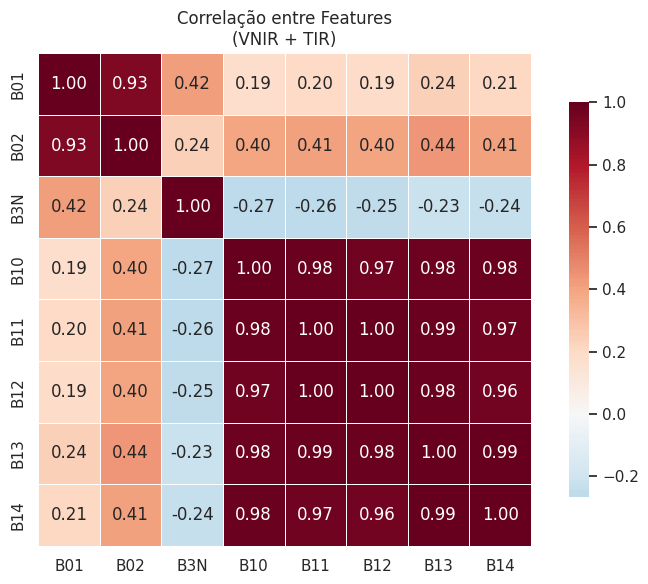

In [6]:
# [Célula 6]
# ── Heatmap: correlação entre features (VNIR + TIR) ────────────────────────
fig, ax = plt.subplots(figsize=(8, 6))
corr_ff = df_clean[FEATURES].corr()
sns.heatmap(corr_ff, annot=True, fmt='.2f', cmap='RdBu_r', center=0,
            ax=ax, square=True, linewidths=0.5, cbar_kws={'shrink': 0.8})
ax.set_title('Correlação entre Features\n(VNIR + TIR)', fontsize=12)
plt.tight_layout()
salvar(plt.gcf(), '6', 'correlacao_features')
plt.show()

figura → models/sazonal_seco_hm_razao/figuras/c7_correlacao_features_swir.png


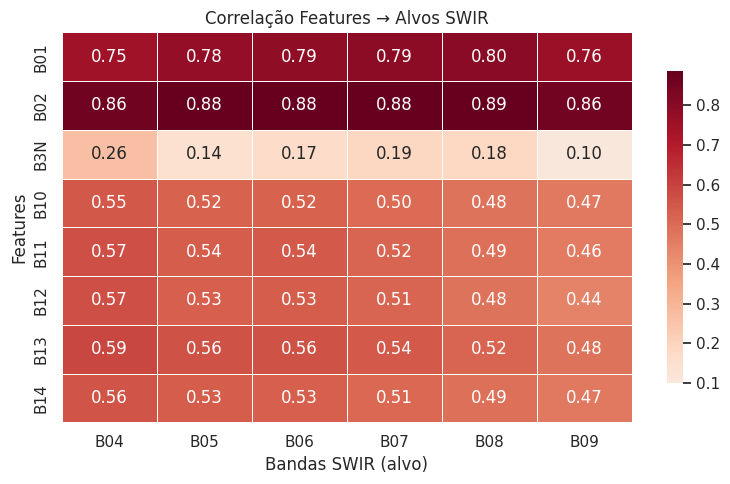

In [7]:
# [Célula 7]
# ── Heatmap: correlação cruzada features → alvos SWIR ──────────────────────
fig, ax = plt.subplots(figsize=(8, 5))
corr_ft = df_clean[FEATURES + TARGETS].corr().loc[FEATURES, TARGETS]
sns.heatmap(corr_ft, annot=True, fmt='.2f', cmap='RdBu_r', center=0,
            ax=ax, linewidths=0.5, cbar_kws={'shrink': 0.8})
ax.set_title('Correlação Features → Alvos SWIR', fontsize=12)
ax.set_xlabel('Bandas SWIR (alvo)')
ax.set_ylabel('Features')
plt.tight_layout()
salvar(plt.gcf(), '7', 'correlacao_features_swir')
plt.show()

figura → models/sazonal_seco_hm_razao/figuras/c8_distribuicao_swir.png


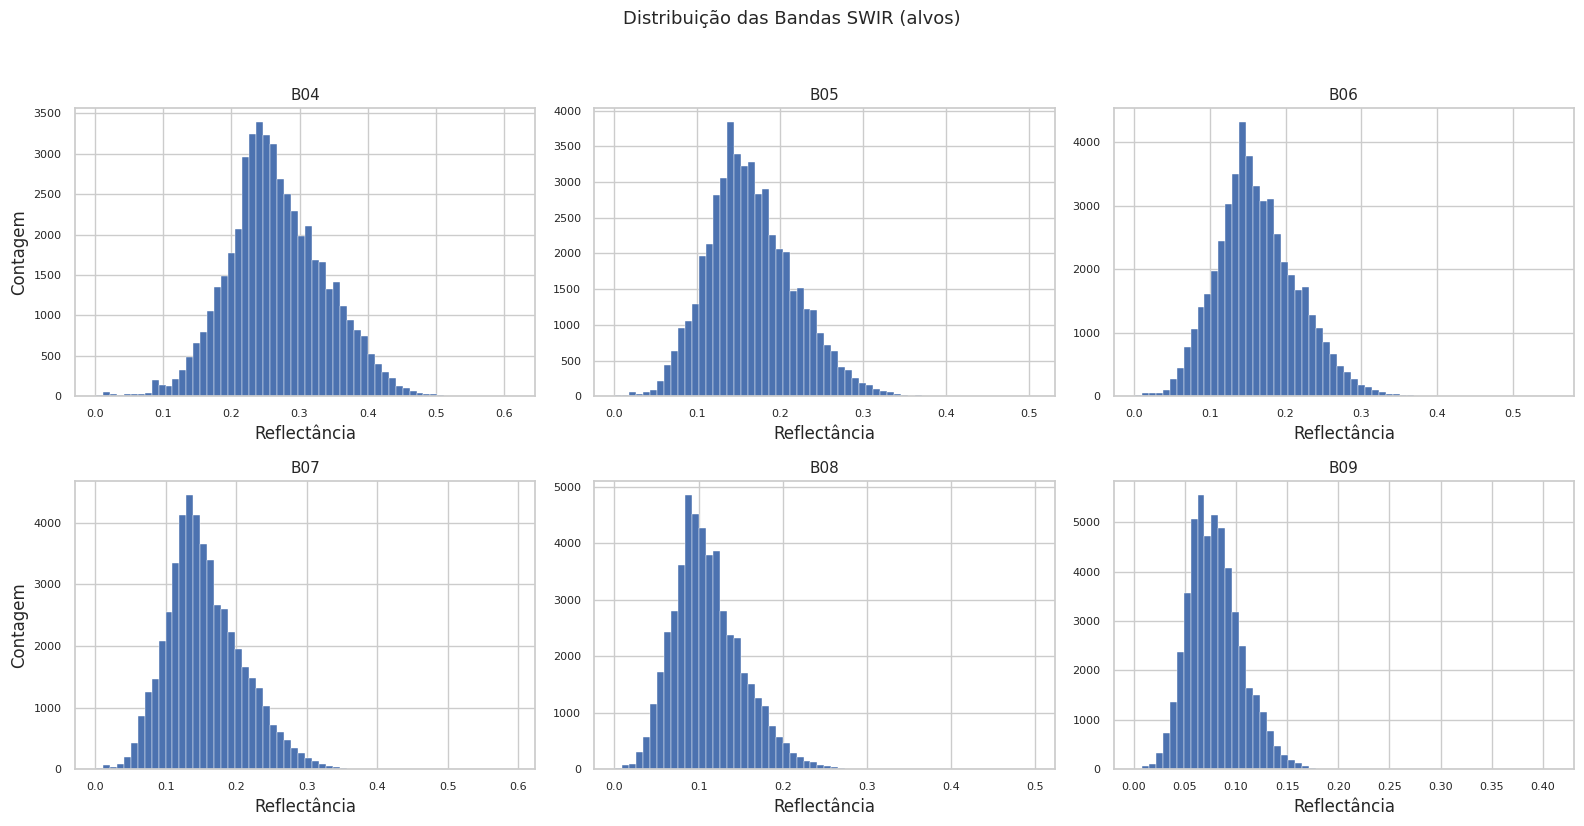

In [8]:
# [Célula 8]
# ── Distribuição das bandas SWIR (alvos) ───────────────────────────────────
fig, axes = plt.subplots(2, 3, figsize=(16, 8), sharey=False)
for ax, banda in zip(axes.flat, TARGETS):
    ax.hist(df_clean[banda], bins=60, color='#4C72B0', edgecolor='white', linewidth=0.3)
    ax.set_title(banda, fontsize=11)
    ax.set_xlabel('Reflectância')
    if ax in axes[:, 0]:          # 1ª coluna de cada linha
        ax.set_ylabel('Contagem')
    ax.tick_params(labelsize=8)
plt.suptitle('Distribuição das Bandas SWIR (alvos)', y=1.03, fontsize=13)
plt.tight_layout()
salvar(plt.gcf(), '8', 'distribuicao_swir')
plt.show()

In [9]:
# [Célula 9]
# ── Split treino/teste + StandardScaler ─────────────────────────────────────
X_tr, X_te, Y_tr, Y_te = train_test_split(
    X_all, Y_all, test_size=0.2, random_state=SEED
)
print(f'Treino: {X_tr.shape[0]:,}  |  Teste: {X_te.shape[0]:,}')

scaler  = StandardScaler()
X_tr_s  = scaler.fit_transform(X_tr)
X_te_s  = scaler.transform(X_te)

kf = KFold(n_splits=N_CV, shuffle=True, random_state=SEED)

# Utilitários compartilhados
def rmse(y_true, y_pred):
    return float(np.sqrt(mean_squared_error(y_true, y_pred)))

def avaliar(y_true, y_pred):
    return {
        'r2'  : float(r2_score(y_true, y_pred)),
        'rmse': rmse(y_true, y_pred),
        'mae' : float(mean_absolute_error(y_true, y_pred)),
    }

Treino: 39,974  |  Teste: 9,994


In [10]:
# [Célula 9A]
# ── Plot StandardScaler para visualização ─────────────────────────────────────

def plot_scatter(preds_dict, Y_te_arr, titulo, cor, celula=None, nome=None):
    fig, axes = plt.subplots(2, 3, figsize=(14, 8))
    np.random.seed(SEED)
    for ax, banda in zip(axes.flat, TARGETS):
        j     = TARGETS.index(banda)
        y_t   = Y_te_arr[:, j]
        y_p   = preds_dict[banda]
        idx   = np.random.choice(len(y_t), min(6000, len(y_t)), replace=False)
        ax.scatter(y_t[idx], y_p[idx], alpha=0.25, s=4, color=cor)
        vmin, vmax = min(y_t.min(), y_p.min()), max(y_t.max(), y_p.max())
        ax.plot([vmin, vmax], [vmin, vmax], 'r--', lw=1.5)
        m = avaliar(y_t, y_p)
        ax.set_title(f'{banda}  R²={m["r2"]:.4f}  RMSE={m["rmse"]:.5f}', fontsize=9)
        ax.set_xlabel('Observado'); ax.set_ylabel('Estimado')
    plt.suptitle(titulo, fontsize=13, y=1.01)
    plt.tight_layout()
    if celula is not None:
        salvar(fig, celula, nome or 'dispersao')
    plt.show()

print('função construida OK')

função construida OK


## 3. PLS — Partial Least Squares

**O que é.** A regressão PLS (*Partial Least Squares*, `sklearn.cross_decomposition.PLSRegression`)
é um modelo **linear** que, em vez de regredir o alvo diretamente sobre as 8 bandas de entrada,
primeiro as resume em poucas **componentes latentes** — combinações lineares das features
escolhidas para ter **máxima covariância com o alvo** — e depois ajusta a regressão sobre essas
componentes.

**Por que usar aqui.**
- As bandas VNIR (B01, B02, B3N) e TIR (B10–B14) são fortemente **colineares** entre si
  (ver heatmap da Célula 6); a PLS lida bem com isso, ao contrário da regressão linear comum,
  que fica instável com features redundantes.
- Diferente da PCA, as componentes são construídas olhando para o alvo SWIR, não só para a
  variância das entradas.
- Por ser linear, simples e rápida, serve como **linha de base**: XGBoost e RF (seções 4 e 5)
  só se justificam se superarem a PLS.

**Como é ajustada neste notebook.**
- Um modelo independente por banda SWIR (B04…B09), sobre as features padronizadas
  (`StandardScaler`, Célula 9).
- Único hiperparâmetro: `n_components`, testado de 1 até `len(FEATURES)` e escolhido pelo menor
  **RMSE médio na validação cruzada** (`KFold`, `N_CV` folds) dentro do conjunto de treino.
- O modelo final é re-treinado no treino inteiro com o `n_components` escolhido e avaliado no
  conjunto de teste (R², RMSE, MAE).

**Limitação.** A PLS só captura relações lineares entre VNIR/TIR e SWIR; respostas SWIR
não-lineares (diferentes minerais com VNIR/TIR parecidos) ficam fora do seu alcance.

In [11]:
print("lembrete das Features com dados nos dois períodos (A e B) >> ", FEATURES)
print("lembrete das TARGETs a serem estimadas no B (2009–2020) >>", TARGETS)

lembrete das Features com dados nos dois períodos (A e B) >>  ['B01', 'B02', 'B3N', 'B10', 'B11', 'B12', 'B13', 'B14']
lembrete das TARGETs a serem estimadas no B (2009–2020) >> ['B04', 'B05', 'B06', 'B07', 'B08', 'B09']


In [12]:
# [Célula 10]
pls_models  = {}
pls_preds   = {}
pls_metrics = {}
pls_params  = {}
MAX_COMP    = len(FEATURES)

for j, banda in enumerate(TARGETS):
    y_tr_j = Y_tr[:, j]
    y_te_j = Y_te[:, j]

    # Busca n_components por CV-RMSE
    best_nc, best_cv = 1, float('inf')
    cv_curve = []
    for nc in range(1, MAX_COMP + 1):
        fold_rmses = []
        for tr_idx, val_idx in kf.split(X_tr_s):
            m = PLSRegression(n_components=nc)
            m.fit(X_tr_s[tr_idx], y_tr_j[tr_idx])
            fold_rmses.append(rmse(y_tr_j[val_idx], m.predict(X_tr_s[val_idx]).ravel()))
        media = float(np.mean(fold_rmses))
        cv_curve.append(media)
        if media < best_cv:
            best_cv, best_nc = media, nc

    modelo = PLSRegression(n_components=best_nc)
    modelo.fit(X_tr_s, y_tr_j)
    y_pred = modelo.predict(X_te_s).ravel()

    pls_models[banda]  = modelo
    pls_preds[banda]   = y_pred
    pls_metrics[banda] = avaliar(y_te_j, y_pred)
    pls_params[banda]  = {'n_components': best_nc, 'cv_rmse': best_cv}
    print(f'{banda}  n_components={best_nc}  CV-RMSE={best_cv:.5f}  R²={pls_metrics[banda]["r2"]:.4f}')

print('\nPLS concluído para as targets ', TARGETS)

B04  n_components=8  CV-RMSE=0.02851  R²=0.8411
B05  n_components=8  CV-RMSE=0.02216  R²=0.8262
B06  n_components=8  CV-RMSE=0.02200  R²=0.8328
B07  n_components=8  CV-RMSE=0.02270  R²=0.8268
B08  n_components=8  CV-RMSE=0.01746  R²=0.8276
B09  n_components=8  CV-RMSE=0.01225  R²=0.7915

PLS concluído para as targets  ['B04', 'B05', 'B06', 'B07', 'B08', 'B09']


In [13]:
# [Célula 11]
# ── PLS: n_components escolhido por banda ──────────────────────────────────
from pprint import pprint
if 'pls_params' not in globals():
    raise RuntimeError('pls_params/pls_models não existem neste kernel (foi reiniciado?). '
                       'Rode as células 1 a 10 antes desta.')

display(pd.DataFrame([
    {'Banda': b, 'n_components': pls_params[b]['n_components'],
     'CV-RMSE': round(pls_params[b]['cv_rmse'], 6),
     'R² teste': round(pls_metrics[b]['r2'], 4),
     'RMSE teste': round(pls_metrics[b]['rmse'], 6)}
    for b in TARGETS
]).set_index('Banda').style.background_gradient(cmap='RdYlGn', subset=['R² teste']))

# Composição das componentes escolhidas: peso de cada feature (padronizada)
# em cada componente latente — x_rotations_ projeta X direto nos scores.
componentes_pls = {
    banda: {
        'n_components': pls_params[banda]['n_components'],
        'componentes': {
            f'comp_{k + 1}': {
                feat: round(float(peso), 3)
                for feat, peso in zip(FEATURES, pls_models[banda].x_rotations_[:, k])
            }
            for k in range(pls_params[banda]['n_components'])
        },
    }
    for banda in TARGETS
}
# pprint(componentes_pls, sort_dicts=False)

,n_components,CV-RMSE,R² teste,RMSE teste
Banda,,,,
B04,8,0.028513,0.841100,0.028529
B05,8,0.022162,0.826200,0.021945
B06,8,0.022002,0.832800,0.021880
B07,8,0.022699,0.826800,0.022344
B08,8,0.017459,0.827600,0.017087
B09,8,0.012254,0.791500,0.012005


figura → models/sazonal_seco_hm_razao/figuras/c11A_pls_componentes.png


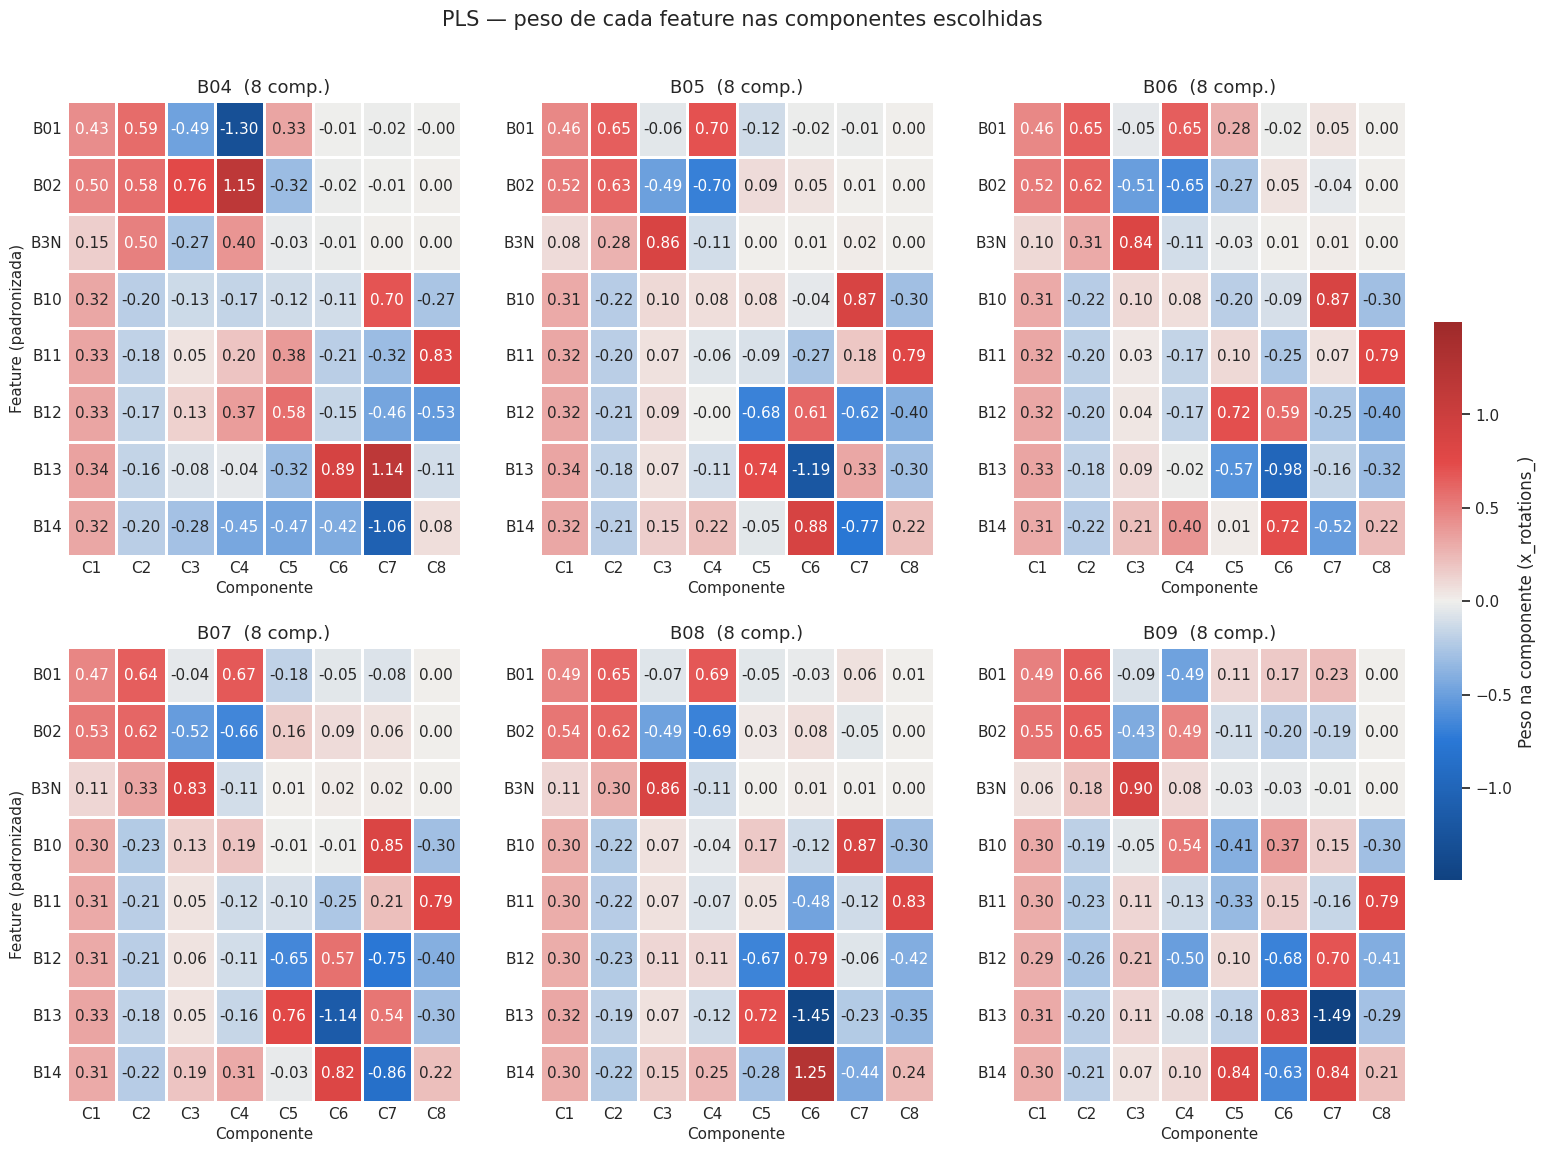

In [14]:
# [Célula 11A]
# ── PLS: composição das componentes (heatmap por banda SWIR) ───────────────
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
if 'pls_params' not in globals():
    raise RuntimeError('pls_params/pls_models não existem neste kernel (foi reiniciado?). '
                       'Rode as células 1 a 10 antes desta.')

# Divergente azul ↔ vermelho com meio cinza neutro (peso ≈ 0 = "nada")
cmap_div = LinearSegmentedColormap.from_list(
    'azul_cinza_vermelho', ['#104281', '#2a78d6', '#f0efec', '#e34948', '#9e2a2a']
)
# Escala simétrica e comum a todos os painéis → cores comparáveis entre bandas
lim = max(
    float(np.abs(pls_models[b].x_rotations_[:, :pls_params[b]['n_components']]).max())
    for b in TARGETS
)
norm = TwoSlopeNorm(vmin=-lim, vcenter=0.0, vmax=lim)

n_comp = [pls_params[b]['n_components'] for b in TARGETS]
fig, axes = plt.subplots(2, 3, figsize=(18, 13))
for ax, banda, k in zip(axes.flat, TARGETS, n_comp):
    pesos = pd.DataFrame(
        pls_models[banda].x_rotations_[:, :k], index=FEATURES,
        columns=[f'C{i + 1}' for i in range(k)],
    )
    sns.heatmap(pesos, ax=ax, cmap=cmap_div, norm=norm, cbar=False,
                annot=True, fmt='.2f', annot_kws={'fontsize': 11},
                linewidths=2, linecolor='white')
    ax.set_title(f'{banda}  ({k} comp.)', fontsize=13)
    ax.set_xlabel('Componente', fontsize=11)
    ax.tick_params(axis='x', rotation=0, length=0, labelsize=11)
    ax.tick_params(axis='y', rotation=0, length=0, labelsize=11)
for ax in axes[:, 0]:
    ax.set_ylabel('Feature (padronizada)', fontsize=11)

cbar = fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=cmap_div),
                    ax=axes.ravel().tolist(), fraction=0.02, pad=0.02)
cbar.set_label('Peso na componente (x_rotations_)')
cbar.outline.set_visible(False)
fig.suptitle('PLS — peso de cada feature nas componentes escolhidas', fontsize=15, y=0.95)
salvar(plt.gcf(), '11A', 'pls_componentes')
plt.show()

figura → models/sazonal_seco_hm_razao/figuras/c12_pls_dispersao.png


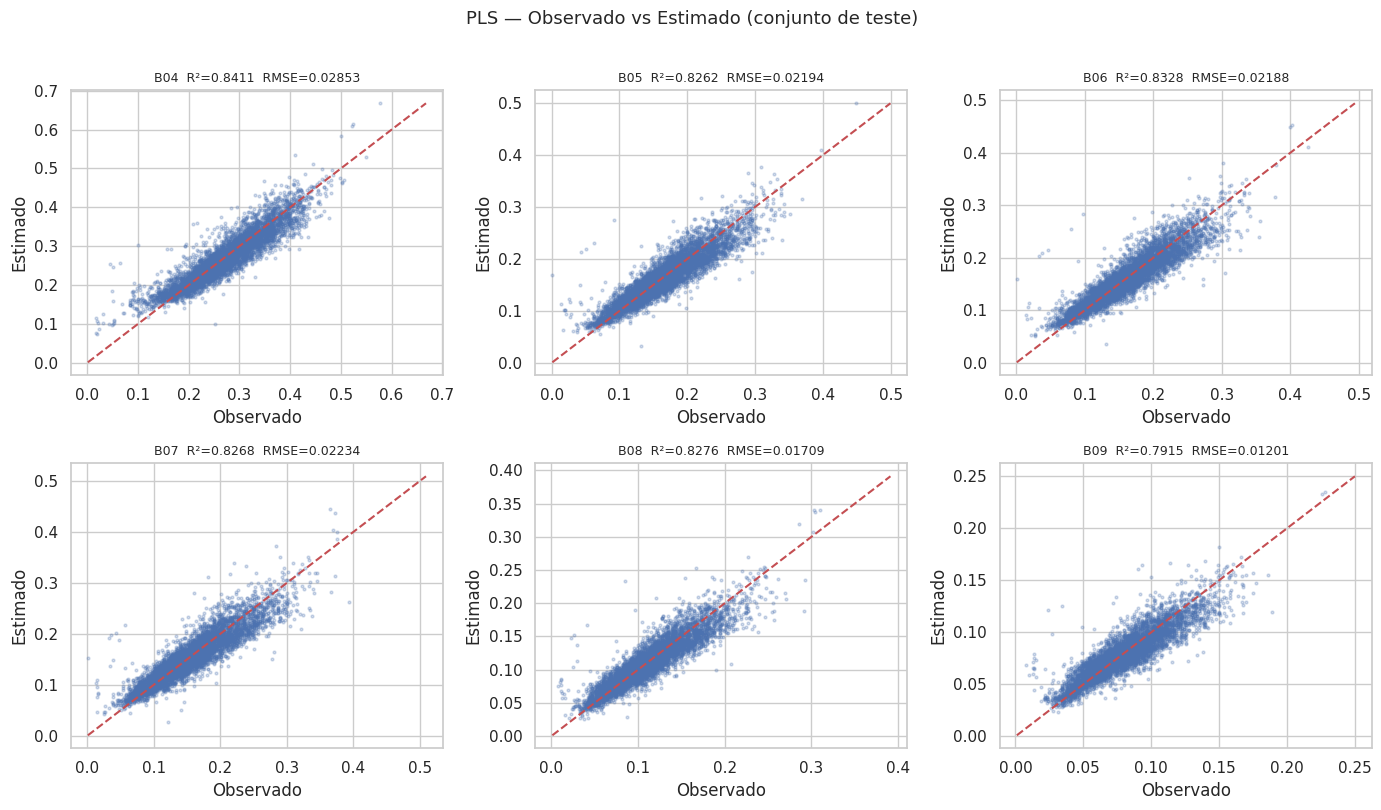

In [15]:
# [Célula 12]
plot_scatter(pls_preds, Y_te, 'PLS — Observado vs Estimado (conjunto de teste)', '#4C72B0', celula='12', nome='pls_dispersao')

figura → models/sazonal_seco_hm_razao/figuras/c12A_assinaturas_pontos_pareados_grupo1.png


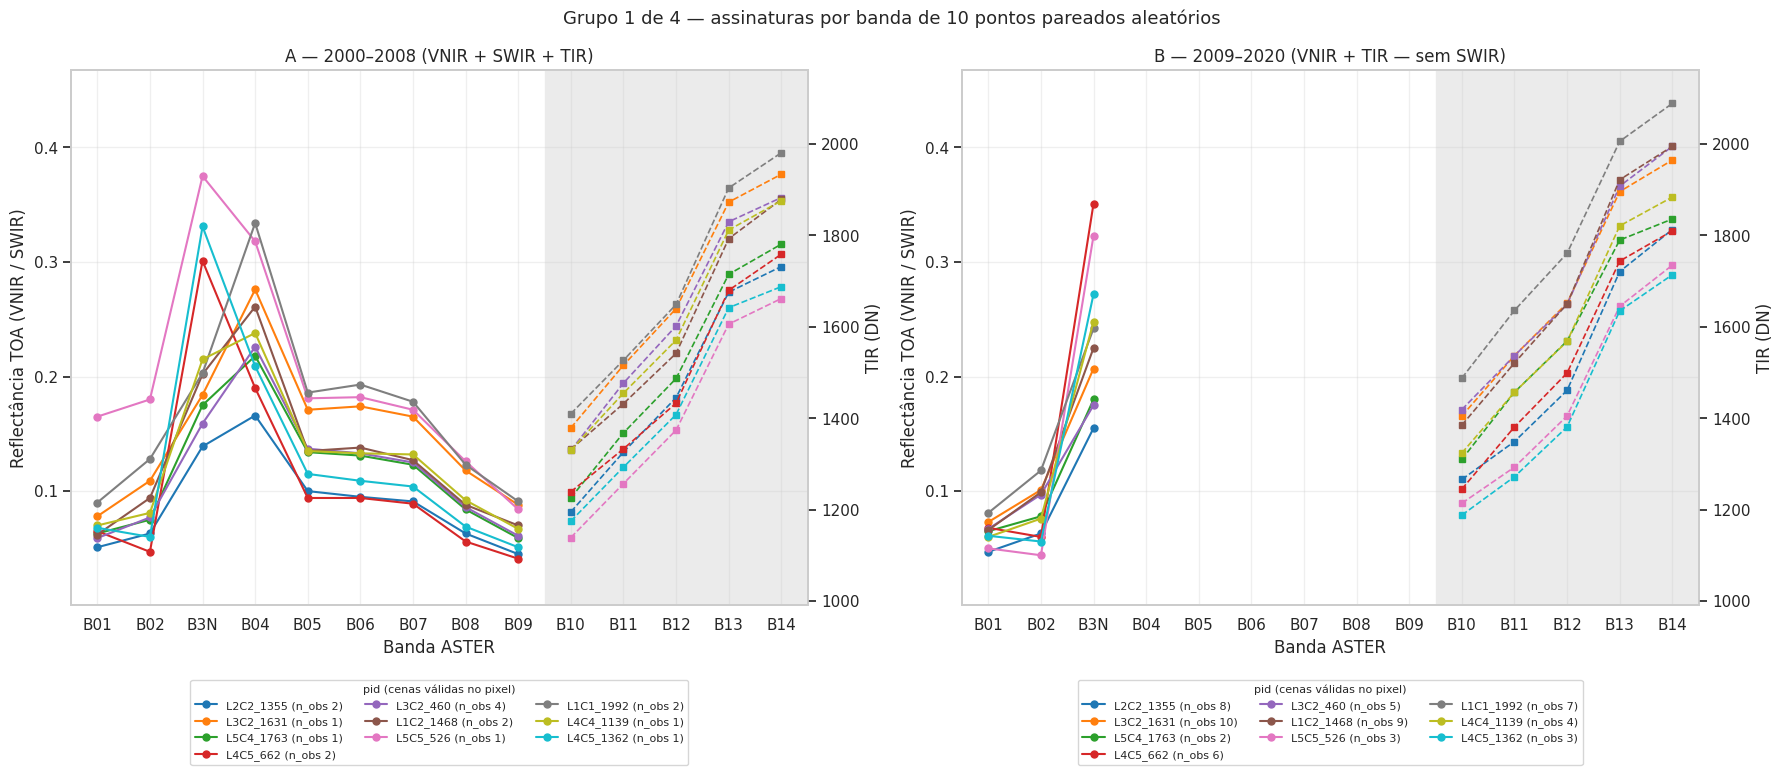

figura → models/sazonal_seco_hm_razao/figuras/c12A_assinaturas_pontos_pareados_grupo2.png


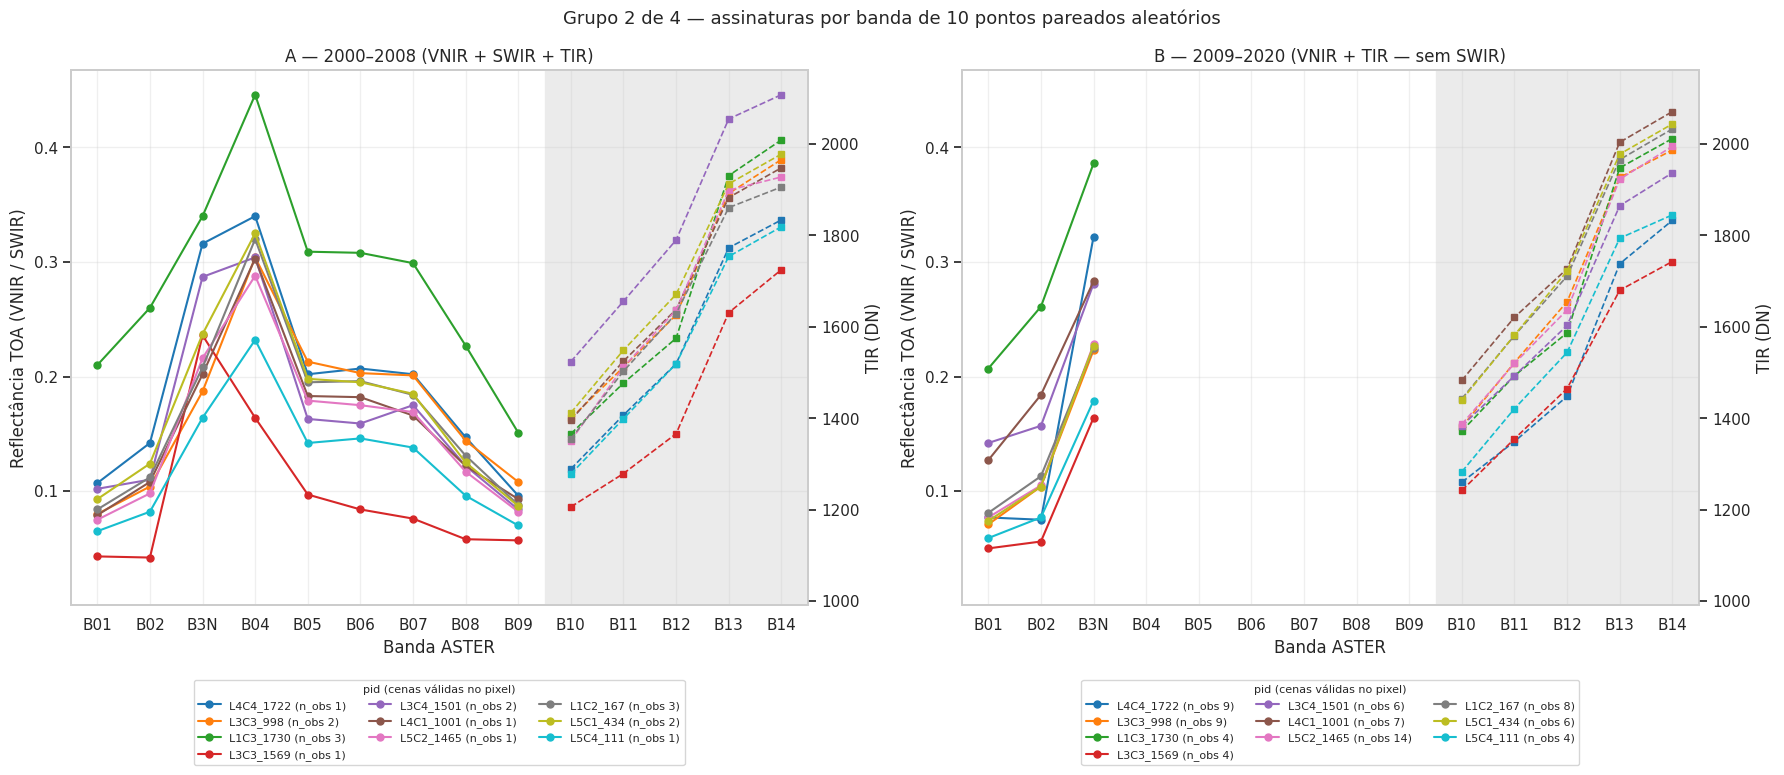

figura → models/sazonal_seco_hm_razao/figuras/c12A_assinaturas_pontos_pareados_grupo3.png


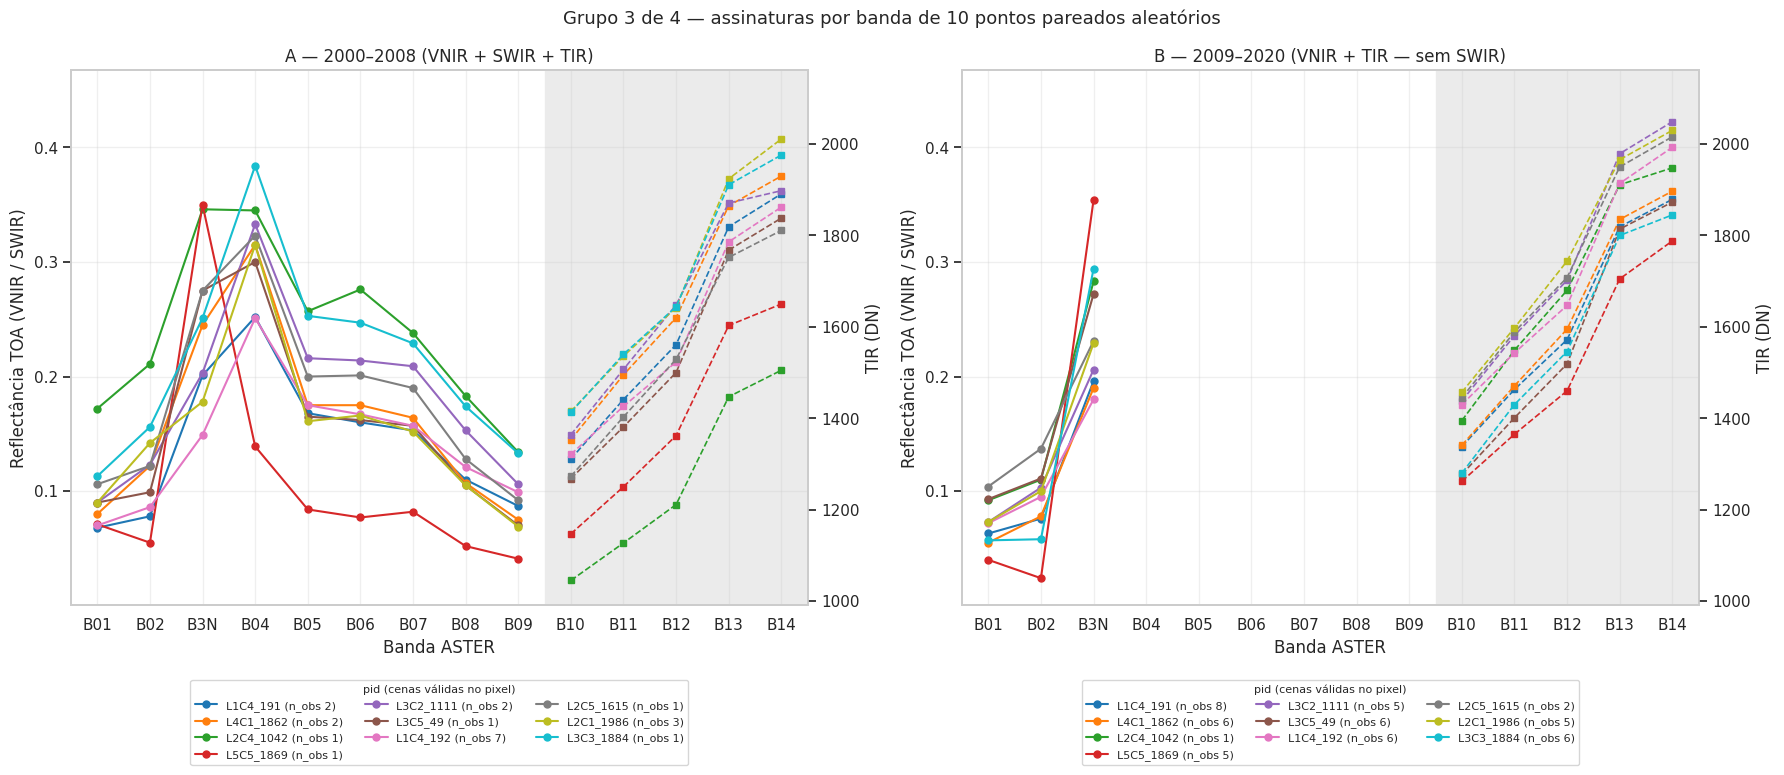

figura → models/sazonal_seco_hm_razao/figuras/c12A_assinaturas_pontos_pareados_grupo4.png


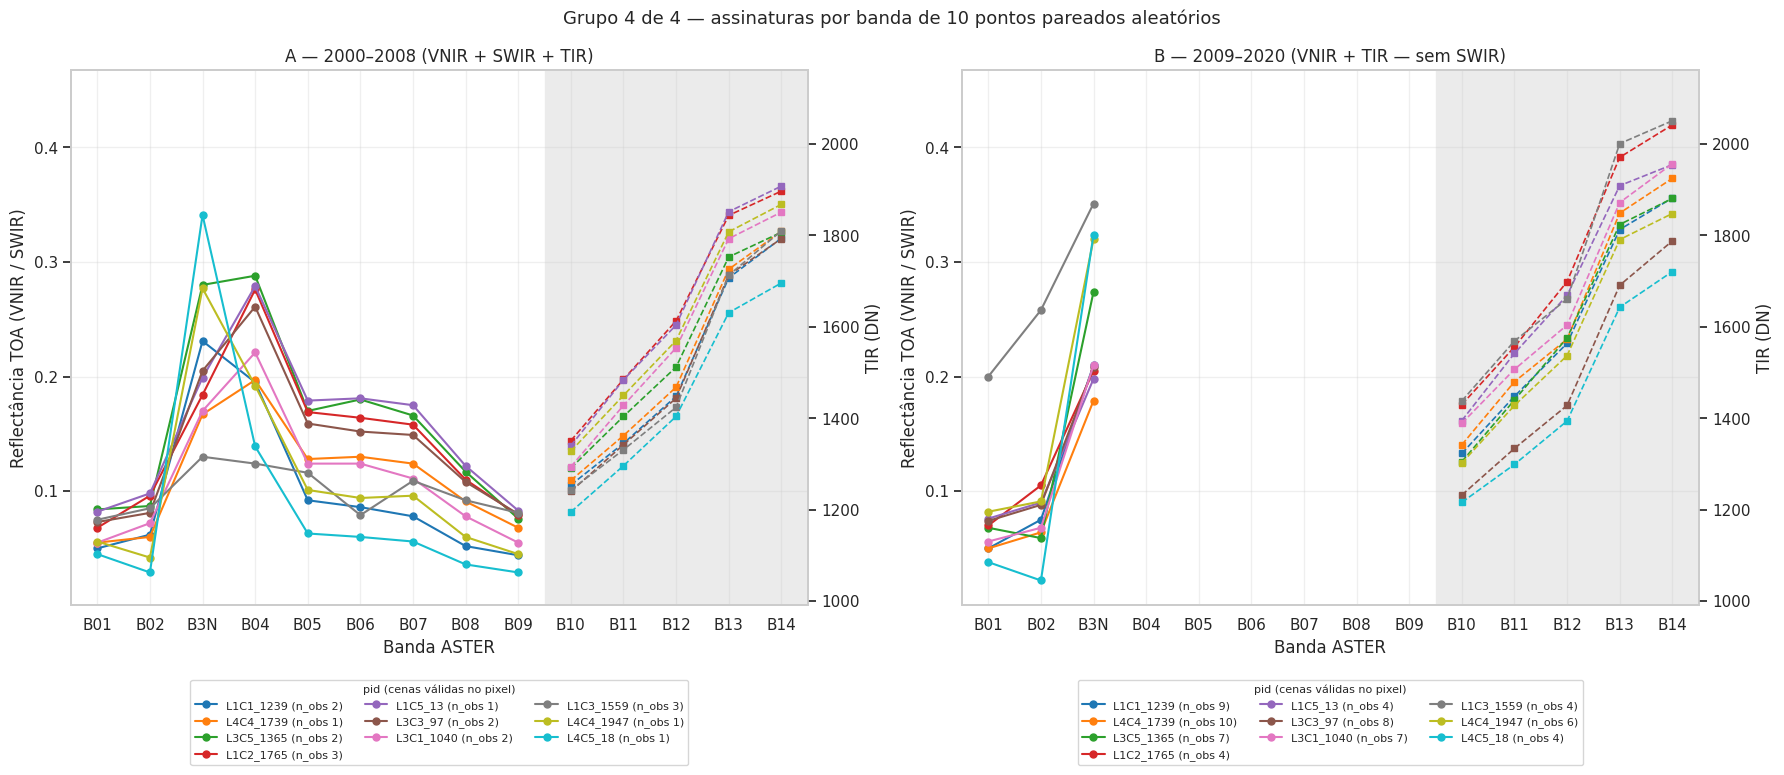

In [16]:
# [Célula 12A]
# ── Assinaturas por banda: N_GRUPOS grupos de N_PONTOS pontos aleatórios ──────
# Um gráfico por grupo: A (esq.) × B (dir.). Pontos diferentes em cada grupo;
# mesmos pontos (pid) e mesma cor nos dois painéis. B sem SWIR.
# Eixo y esquerdo: reflectância (VNIR/SWIR, linha cheia); direito: TIR em DN (tracejado).
# Escalas iguais em todos os gráficos, para comparar os grupos.
N_GRUPOS    = 4
N_PONTOS    = 10
SEED_PONTOS = SEED     # None → sorteia pontos novos a cada execução

VNIR  = ['B01', 'B02', 'B3N']
SWIR  = ['B04', 'B05', 'B06', 'B07', 'B08', 'B09']
TIR   = ['B10', 'B11', 'B12', 'B13', 'B14']
ORDEM = VNIR + SWIR + TIR
POS   = {b: i for i, b in enumerate(ORDEM)}   # mesma posição de banda nos dois painéis
PAINEIS = [('_A', VNIR + SWIR, 'A — 2000–2008 (VNIR + SWIR + TIR)'),
           ('_B', VNIR,        'B — 2009–2020 (VNIR + TIR — sem SWIR)')]

df_pts = pd.read_csv(CSV_PAREADOS)
if CELULAS:
    df_pts = df_pts[df_pts['celula_nome'].isin(CELULAS)]
df_pts = df_pts[(df_pts['n_obs_A'] >= N_OBS_MIN) & (df_pts['n_obs_B'] >= N_OBS_MIN)]
df_pts = escalar(escalar(df_pts, '_A'), '_B').sample(N_GRUPOS * N_PONTOS, random_state=SEED_PONTOS)


def limites(colunas, folga=0.05):
    v = df_pts[colunas].to_numpy()
    lo, hi = np.nanmin(v), np.nanmax(v)
    return lo - folga * (hi - lo), hi + folga * (hi - lo)

lim_r = limites([b + s for s, refl, _ in PAINEIS for b in refl])
lim_t = limites([b + s for s, _, _ in PAINEIS for b in TIR])
cores_pts = plt.cm.tab10(np.linspace(0, 1, N_PONTOS))


def plot_grupo(grupo, g):
    fig, axes = plt.subplots(1, 2, figsize=(18, 8))
    for ax, (suf, refl, titulo) in zip(axes, PAINEIS):
        ax_t = ax.twinx()
        for cor, (_, p) in zip(cores_pts, grupo.iterrows()):
            ax.plot([POS[b] for b in refl], [p[b + suf] for b in refl],
                    'o-', color=cor, lw=1.5, ms=5, label=f'{p["pid"]} (n_obs {int(p["n_obs" + suf])})')
            ax_t.plot([POS[b] for b in TIR], [p[b + suf] for b in TIR],
                      's--', color=cor, lw=1.2, ms=4)
        ax.axvspan(POS['B10'] - 0.5, POS['B14'] + 0.5, color='0.92', zorder=0)
        ax.set_xticks(range(len(ORDEM)), ORDEM)
        ax.set_xlim(-0.5, len(ORDEM) - 0.5)
        ax.set_ylim(lim_r)
        ax_t.set_ylim(lim_t)
        ax.set_title(titulo, fontsize=12)
        ax.set_xlabel('Banda ASTER')
        ax.set_ylabel(f'{ROTULO_REFL} (VNIR / SWIR)')
        ax_t.set_ylabel('TIR (DN)')
        ax.grid(alpha=0.3)
        ax_t.grid(False)
        ax.legend(fontsize=8, title='pid (cenas válidas no pixel)', title_fontsize=8, ncol=3,
                  loc='upper center', bbox_to_anchor=(0.5, -0.13))
    plt.suptitle(f'Grupo {g} de {N_GRUPOS} — assinaturas por banda de {len(grupo)} pontos pareados aleatórios',
                 fontsize=13)
    plt.tight_layout()
    salvar(plt.gcf(), '12A', f'assinaturas_pontos_pareados_grupo{g}')
    plt.show()


for g in range(N_GRUPOS):
    plot_grupo(df_pts.iloc[g * N_PONTOS:(g + 1) * N_PONTOS], g + 1)

## 4. XGBoost — Gradient Boosting

`RandomizedSearchCV` com `N_ITER_XGB` iterações e `KFold(N_CV)`. Score: neg_RMSE.

In [17]:
# [Célula 13]
XGB_PARAM_DIST = {
    'n_estimators':     randint(100, 700),
    'max_depth':        randint(3, 10),
    'learning_rate':    uniform(0.01, 0.29),
    'subsample':        uniform(0.5, 0.5),
    'colsample_bytree': uniform(0.5, 0.5),
    'min_child_weight': randint(1, 10),
    'gamma':            uniform(0.0, 0.5),
    'reg_alpha':        uniform(0.0, 1.0),
    'reg_lambda':       uniform(0.5, 1.5),
}

xgb_models  = {}
xgb_preds   = {}
xgb_metrics = {}
xgb_params  = {}

for j, banda in enumerate(TARGETS):
    y_tr_j = Y_tr[:, j]
    y_te_j = Y_te[:, j]

    base = xgb.XGBRegressor(
        tree_method='hist', random_state=SEED, n_jobs=1, verbosity=0
    )
    search = RandomizedSearchCV(
        base, XGB_PARAM_DIST,
        n_iter=N_ITER_XGB, cv=kf,
        scoring='neg_root_mean_squared_error',
        random_state=SEED, n_jobs=N_JOBS,
        refit=True, verbose=0,
    )
    search.fit(X_tr_s, y_tr_j)

    melhor = search.best_estimator_
    y_pred = melhor.predict(X_te_s)

    xgb_models[banda]  = melhor
    xgb_preds[banda]   = y_pred
    xgb_metrics[banda] = avaliar(y_te_j, y_pred)
    xgb_params[banda]  = {**search.best_params_, 'cv_rmse': float(-search.best_score_)}
    print(f'{banda}  R²={xgb_metrics[banda]["r2"]:.4f}  RMSE={xgb_metrics[banda]["rmse"]:.5f}')

print('\nXGBoost concluído')

B04  R²=0.8722  RMSE=0.02558
B05  R²=0.8592  RMSE=0.01975
B06  R²=0.8642  RMSE=0.01972
B07  R²=0.8574  RMSE=0.02028
B08  R²=0.8472  RMSE=0.01609
B09  R²=0.7973  RMSE=0.01184

XGBoost concluído


figura → models/sazonal_seco_hm_razao/figuras/c14_xgb_feature_importance.png


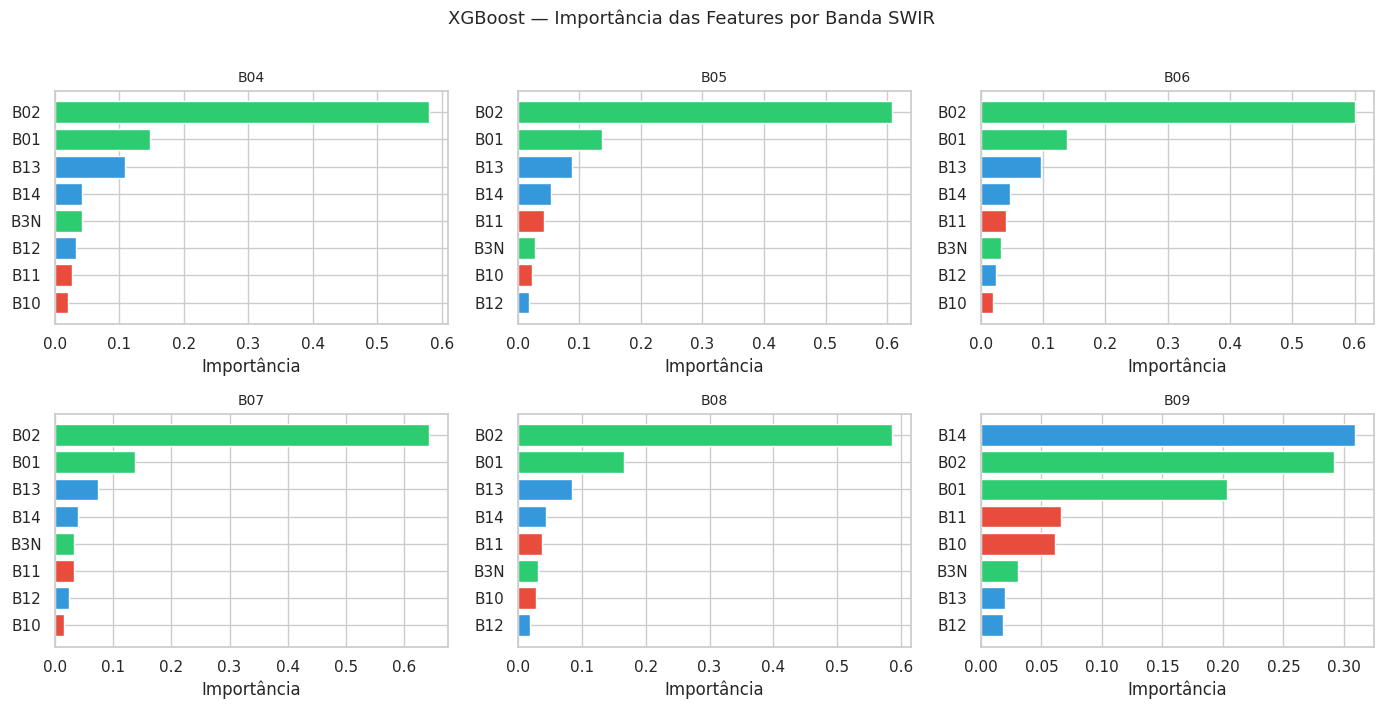

In [18]:
# [Célula 14]
# ── XGBoost: importância das features por banda ────────────────────────────
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, banda in zip(axes.flat, TARGETS):
    importancias = xgb_models[banda].feature_importances_
    idx_sorted   = np.argsort(importancias)[::-1]
    cores        = ['#2ecc71' if i < 3 else '#3498db' if i >= 5 else '#e74c3c'
                    for i in range(len(FEATURES))]
    ax.barh([FEATURES[i] for i in idx_sorted], importancias[idx_sorted],
            color=[cores[i] for i in idx_sorted], edgecolor='white')
    ax.set_title(f'{banda}', fontsize=10)
    ax.set_xlabel('Importância')
    ax.invert_yaxis()
plt.suptitle('XGBoost — Importância das Features por Banda SWIR', fontsize=13, y=1.01)
plt.tight_layout()
salvar(plt.gcf(), '14', 'xgb_feature_importance')
plt.show()

In [19]:
# [Célula 15]
# ── XGBoost: melhores hiperparâmetros ─────────────────────────────────────
pd.DataFrame(xgb_params).T.round(4).style.background_gradient(
    cmap='YlOrRd', subset=['cv_rmse']
)

,colsample_bytree,gamma,learning_rate,max_depth,min_child_weight,n_estimators,reg_alpha,reg_lambda,subsample,cv_rmse
B04,0.795400,0.015300,0.020800,8.000000,6.000000,543.000000,0.326700,1.741800,0.635800,0.025200
B05,0.795400,0.015300,0.020800,8.000000,6.000000,543.000000,0.326700,1.741800,0.635800,0.020000
B06,0.795400,0.015300,0.020800,8.000000,6.000000,543.000000,0.326700,1.741800,0.635800,0.019800
B07,0.795400,0.015300,0.020800,8.000000,6.000000,543.000000,0.326700,1.741800,0.635800,0.020600
B08,0.795400,0.015300,0.020800,8.000000,6.000000,543.000000,0.326700,1.741800,0.635800,0.016400
B09,0.588000,0.009000,0.153200,6.000000,8.000000,491.000000,0.849200,1.486400,0.784200,0.012100


figura → models/sazonal_seco_hm_razao/figuras/c16_xgb_dispersao.png


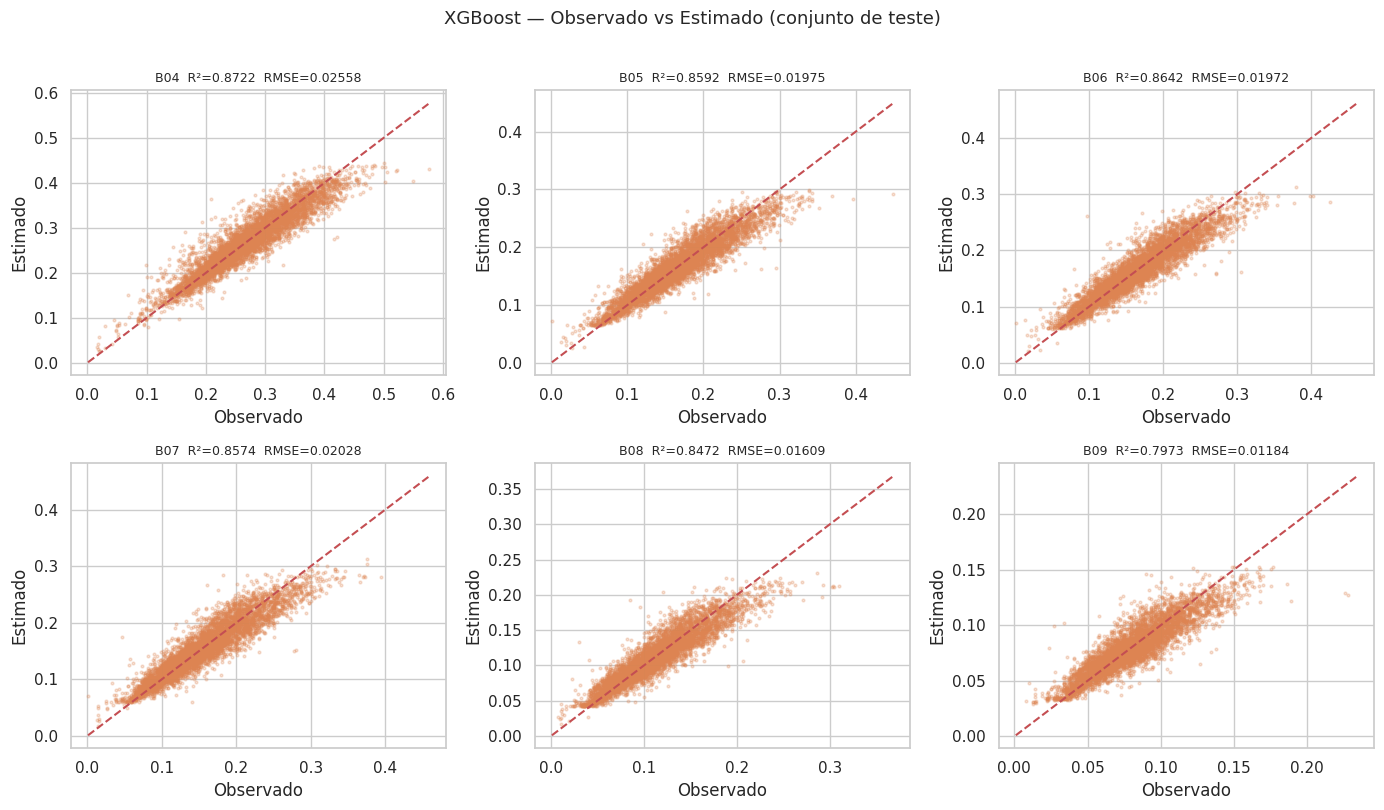

In [20]:
# [Célula 16]
plot_scatter(xgb_preds, Y_te, 'XGBoost — Observado vs Estimado (conjunto de teste)', '#DD8452', celula='16', nome='xgb_dispersao')

## 5. RF — Random Forest

Mesmo modelo do `ee.Classifier.smileRandomForest` (modo `REGRESSION`), para poder levar os
hiperparâmetros escolhidos aqui direto para o GEE. Correspondência:

| scikit-learn | GEE `smileRandomForest` |
|---|---|
| `n_estimators` | `numberOfTrees` |
| `max_features` (nº de features por split) | `variablesPerSplit` |
| `min_samples_leaf` | `minLeafPopulation` |
| `max_samples` (fração do bootstrap) | `bagFraction` |
| `max_leaf_nodes` | `maxNodes` |

`RandomizedSearchCV` com `N_ITER_RF` iterações e `KFold(N_CV)`. Score: neg_RMSE.
RF não depende de escala, mas usa as mesmas features padronizadas dos outros modelos.

In [21]:
# [Célula 17]
RF_PARAM_DIST = {
    'n_estimators':     randint(100, 150),
    'max_features':     randint(2, len(FEATURES) + 1),   # variablesPerSplit
    'min_samples_leaf': randint(1, 10),                  # minLeafPopulation
    'max_samples':      uniform(0.5, 0.5),               # bagFraction
    'max_leaf_nodes':   [None, 256, 1024, 4096],         # maxNodes (None = sem limite)
}

rf_models  = {}
rf_preds   = {}
rf_metrics = {}
rf_params  = {}

for j, banda in enumerate(TARGETS):
    y_tr_j = Y_tr[:, j]
    y_te_j = Y_te[:, j]

    base = RandomForestRegressor(bootstrap=True, random_state=SEED, n_jobs=1)
    search = RandomizedSearchCV(
        base, RF_PARAM_DIST,
        n_iter=N_ITER_RF, cv=kf,
        scoring='neg_root_mean_squared_error',
        random_state=SEED, n_jobs=N_JOBS,
        refit=True, verbose=0,
    )
    search.fit(X_tr_s, y_tr_j)

    melhor = search.best_estimator_
    y_pred = melhor.predict(X_te_s)

    rf_models[banda]  = melhor
    rf_preds[banda]   = y_pred
    rf_metrics[banda] = avaliar(y_te_j, y_pred)
    p = search.best_params_
    rf_params[banda]  = {**p, 'cv_rmse': float(-search.best_score_),
                         'gee': {'numberOfTrees': int(p['n_estimators']),
                                 'variablesPerSplit': int(p['max_features']),
                                 'minLeafPopulation': int(p['min_samples_leaf']),
                                 'bagFraction': round(float(p['max_samples']), 3),
                                 'maxNodes': p['max_leaf_nodes']}}
    print(f'{banda}  R²={rf_metrics[banda]["r2"]:.4f}  RMSE={rf_metrics[banda]["rmse"]:.5f}  '
          f'GEE: {rf_params[banda]["gee"]}')

print('\nRF concluído')

B04  R²=0.8830  RMSE=0.02447  GEE: {'numberOfTrees': 135, 'variablesPerSplit': 6, 'minLeafPopulation': 1, 'bagFraction': 0.517, 'maxNodes': 4096}
B05  R²=0.8822  RMSE=0.01807  GEE: {'numberOfTrees': 108, 'variablesPerSplit': 5, 'minLeafPopulation': 2, 'bagFraction': 0.983, 'maxNodes': None}
B06  R²=0.8841  RMSE=0.01821  GEE: {'numberOfTrees': 108, 'variablesPerSplit': 5, 'minLeafPopulation': 2, 'bagFraction': 0.983, 'maxNodes': None}
B07  R²=0.8804  RMSE=0.01856  GEE: {'numberOfTrees': 108, 'variablesPerSplit': 5, 'minLeafPopulation': 2, 'bagFraction': 0.983, 'maxNodes': None}
B08  R²=0.8794  RMSE=0.01429  GEE: {'numberOfTrees': 108, 'variablesPerSplit': 5, 'minLeafPopulation': 2, 'bagFraction': 0.983, 'maxNodes': None}
B09  R²=0.8613  RMSE=0.00979  GEE: {'numberOfTrees': 108, 'variablesPerSplit': 5, 'minLeafPopulation': 2, 'bagFraction': 0.983, 'maxNodes': None}

RF concluído


figura → models/sazonal_seco_hm_razao/figuras/c18_rf_dispersao.png


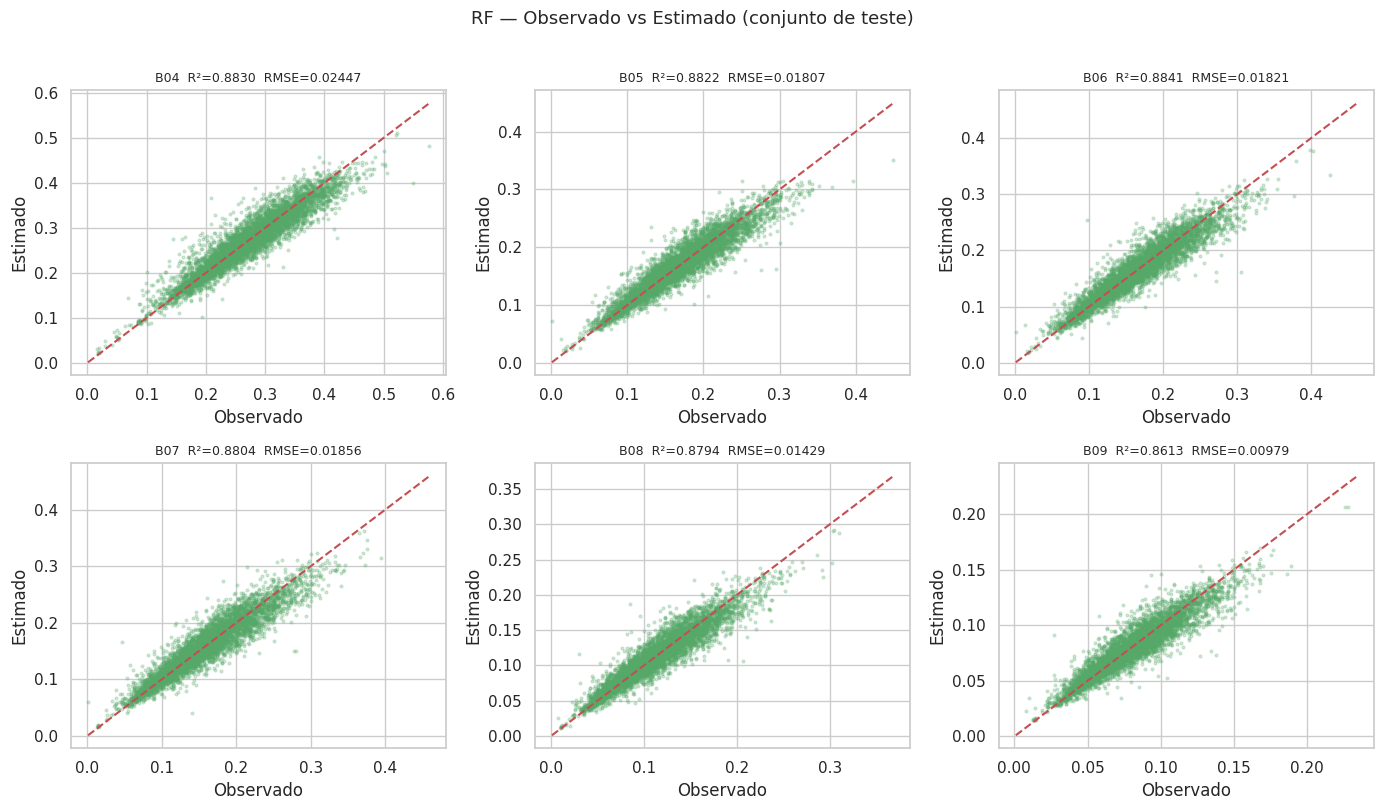

In [23]:
# [Célula 18]
plot_scatter(rf_preds, Y_te, 'RF — Observado vs Estimado (conjunto de teste)', '#55A868', celula='18', nome='rf_dispersao')

## 6. Comparação de Modelos

In [24]:
# [Célula 19]
all_metrics = {'PLS': pls_metrics, 'XGBoost': xgb_metrics, 'RF': rf_metrics}

# Tabela R² comparativa
df_r2 = pd.DataFrame(
    {mod: {b: all_metrics[mod][b]['r2'] for b in TARGETS} for mod in all_metrics}
)
df_r2.index.name = 'Banda'
print('=== R² por modelo e banda ===')
display(df_r2.round(4).style
    .background_gradient(cmap='RdYlGn', vmin=0, vmax=1)
    .format('{:.4f}')
    .set_caption('R² — quanto maior, melhor (máx = 1.0)'))

=== R² por modelo e banda ===


,PLS,XGBoost,RF
Banda,,,
B04,0.8411,0.8722,0.8830
B05,0.8262,0.8592,0.8822
B06,0.8328,0.8642,0.8841
B07,0.8268,0.8574,0.8804
B08,0.8276,0.8472,0.8794
B09,0.7915,0.7973,0.8613


In [25]:
# [Célula 20]
# Tabela RMSE comparativa
df_rmse = pd.DataFrame(
    {mod: {b: all_metrics[mod][b]['rmse'] for b in TARGETS} for mod in all_metrics}
)
df_rmse.index.name = 'Banda'
print('=== RMSE por modelo e banda ===')
display(df_rmse.round(6).style
    .background_gradient(cmap='RdYlGn_r', axis=None)
    .format('{:.6f}')
    .set_caption('RMSE — quanto menor, melhor'))

=== RMSE por modelo e banda ===


,PLS,XGBoost,RF
Banda,,,
B04,0.028529,0.025585,0.024473
B05,0.021945,0.019754,0.018066
B06,0.021880,0.019717,0.018215
B07,0.022344,0.020275,0.018565
B08,0.017087,0.016086,0.014290
B09,0.012005,0.011837,0.009792


figura → models/sazonal_seco_hm_razao/figuras/c21_comparacao_modelos.png


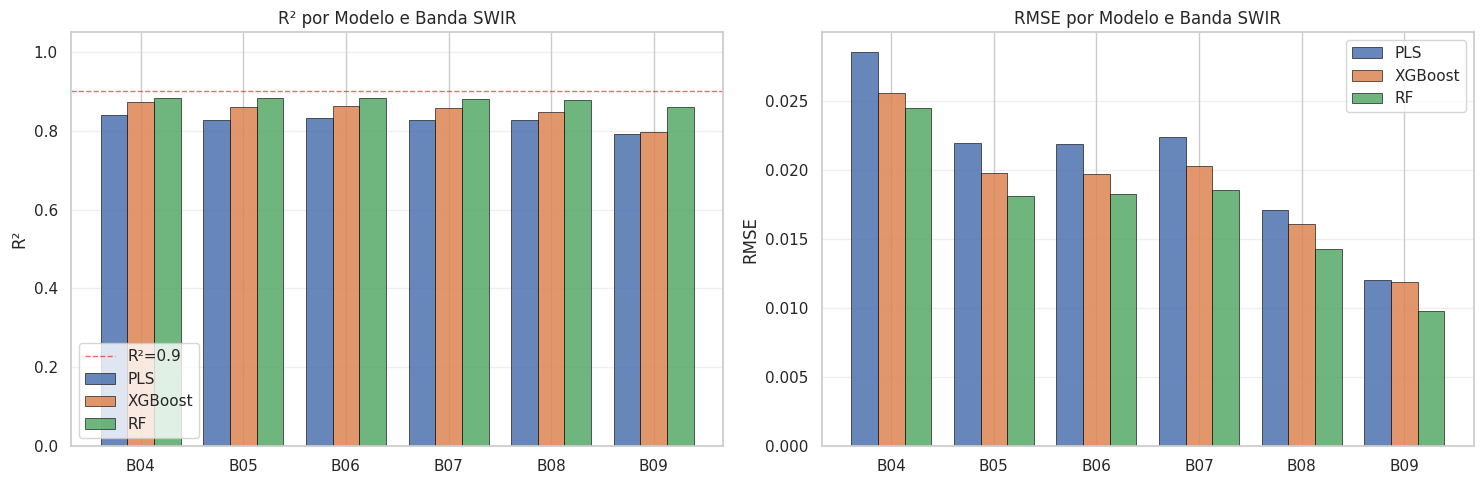

In [26]:
# [Célula 21]
# ── Gráfico de barras agrupado: R² e RMSE ─────────────────────────────────
cores  = {'PLS': '#4C72B0', 'XGBoost': '#DD8452', 'RF': '#55A868'}
x      = np.arange(len(TARGETS))
width  = 0.26

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

for i, (mod, cor) in enumerate(cores.items()):
    r2s   = [all_metrics[mod][b]['r2']   for b in TARGETS]
    rmses = [all_metrics[mod][b]['rmse'] for b in TARGETS]
    ax1.bar(x + i * width, r2s,   width, label=mod, color=cor,
            edgecolor='black', linewidth=0.5, alpha=0.85)
    ax2.bar(x + i * width, rmses, width, label=mod, color=cor,
            edgecolor='black', linewidth=0.5, alpha=0.85)

ax1.set_xticks(x + width); ax1.set_xticklabels(TARGETS)
ax1.set_ylabel('R²'); ax1.set_title('R² por Modelo e Banda SWIR')
ax1.set_ylim(0, 1.05)
ax1.axhline(0.9, color='red', ls='--', lw=1, alpha=0.6, label='R²=0.9')
ax1.legend(); ax1.grid(axis='y', alpha=0.3)

ax2.set_xticks(x + width); ax2.set_xticklabels(TARGETS)
ax2.set_ylabel('RMSE'); ax2.set_title('RMSE por Modelo e Banda SWIR')
ax2.legend(); ax2.grid(axis='y', alpha=0.3)

plt.tight_layout()
salvar(plt.gcf(), '21', 'comparacao_modelos')
plt.show()

figura → models/sazonal_seco_hm_razao/figuras/c21A_assinaturas_swir_estimado_RF_grupo1.png


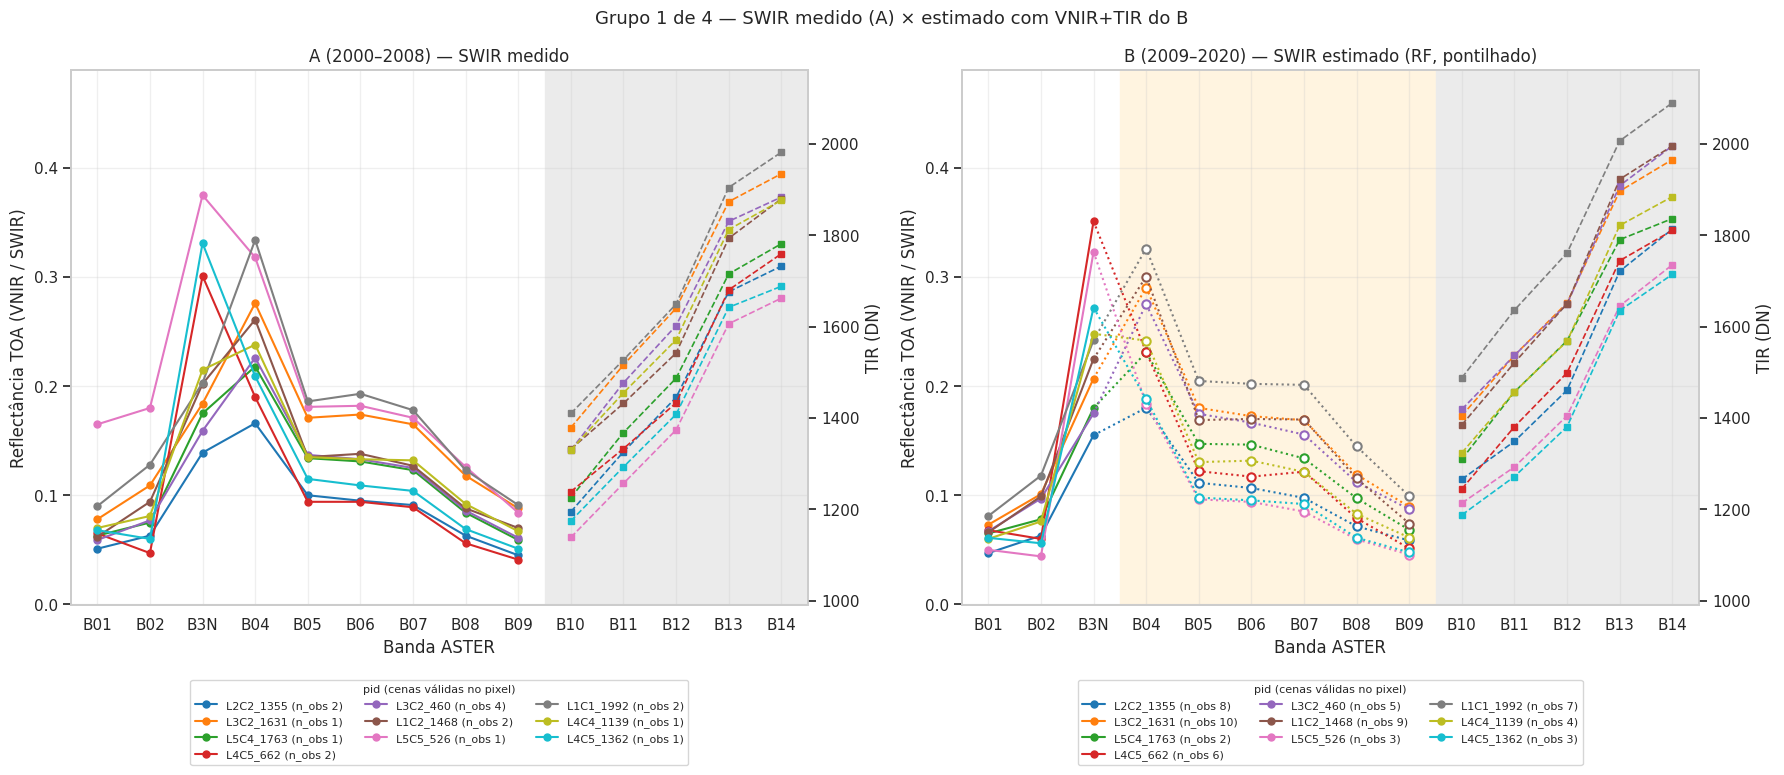

figura → models/sazonal_seco_hm_razao/figuras/c21A_assinaturas_swir_estimado_RF_grupo2.png


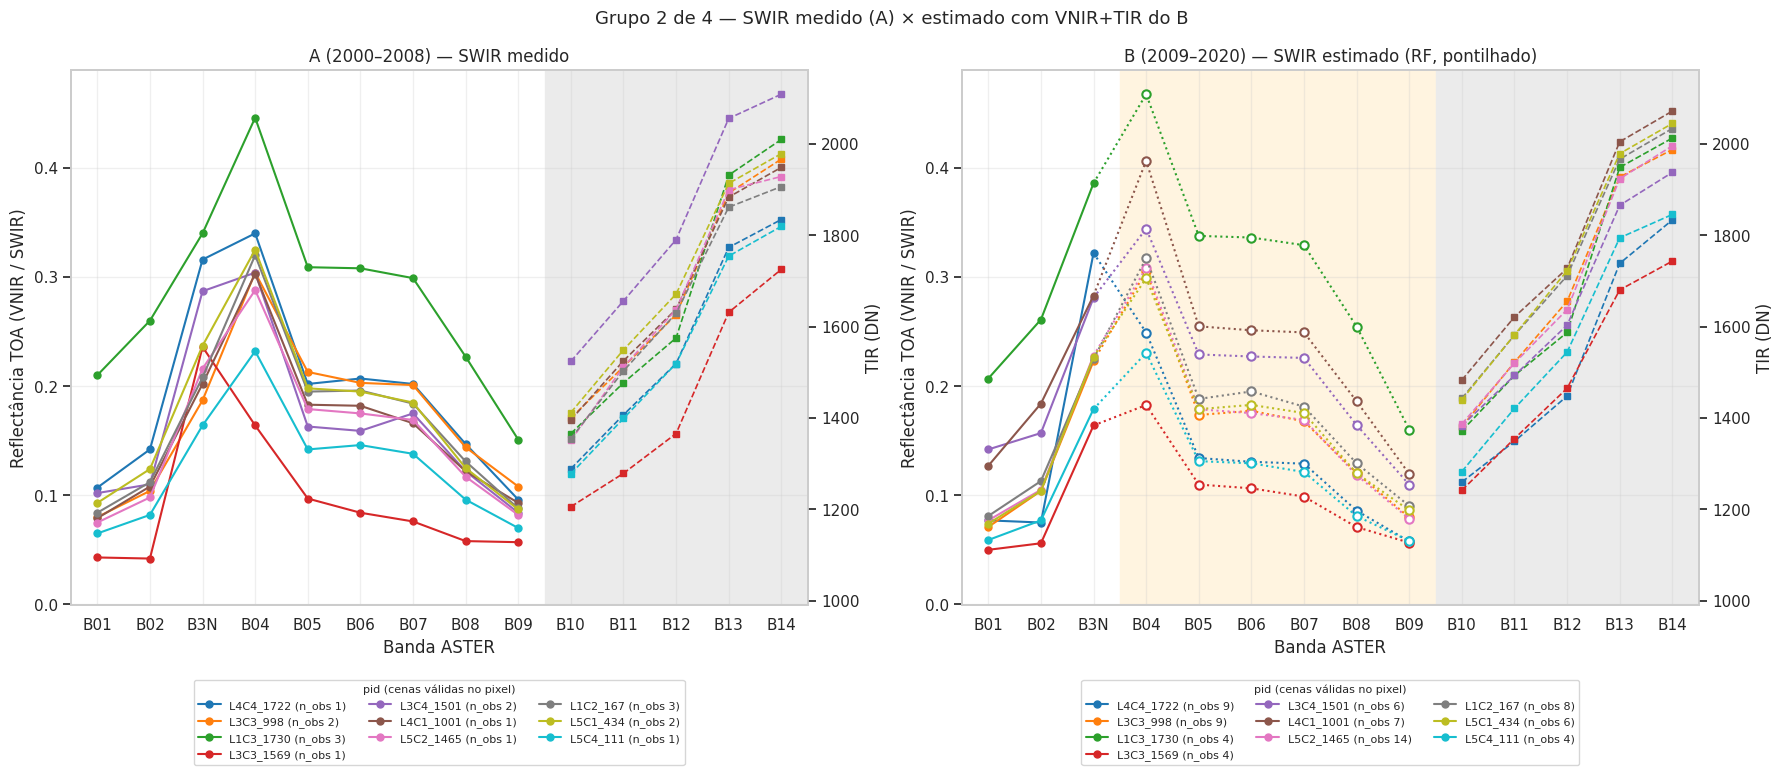

figura → models/sazonal_seco_hm_razao/figuras/c21A_assinaturas_swir_estimado_RF_grupo3.png


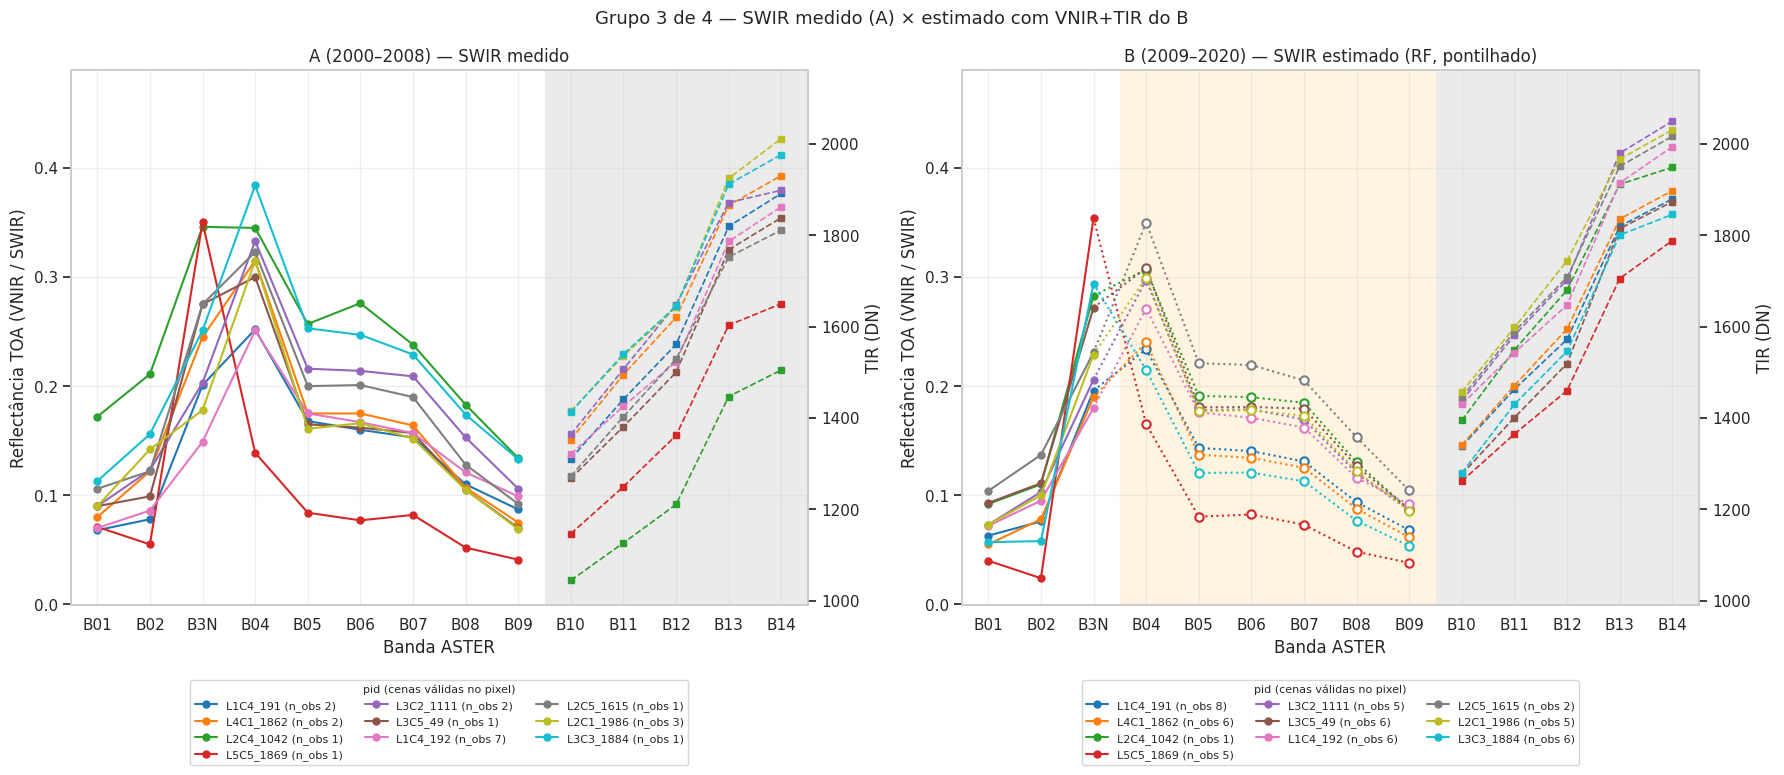

figura → models/sazonal_seco_hm_razao/figuras/c21A_assinaturas_swir_estimado_RF_grupo4.png


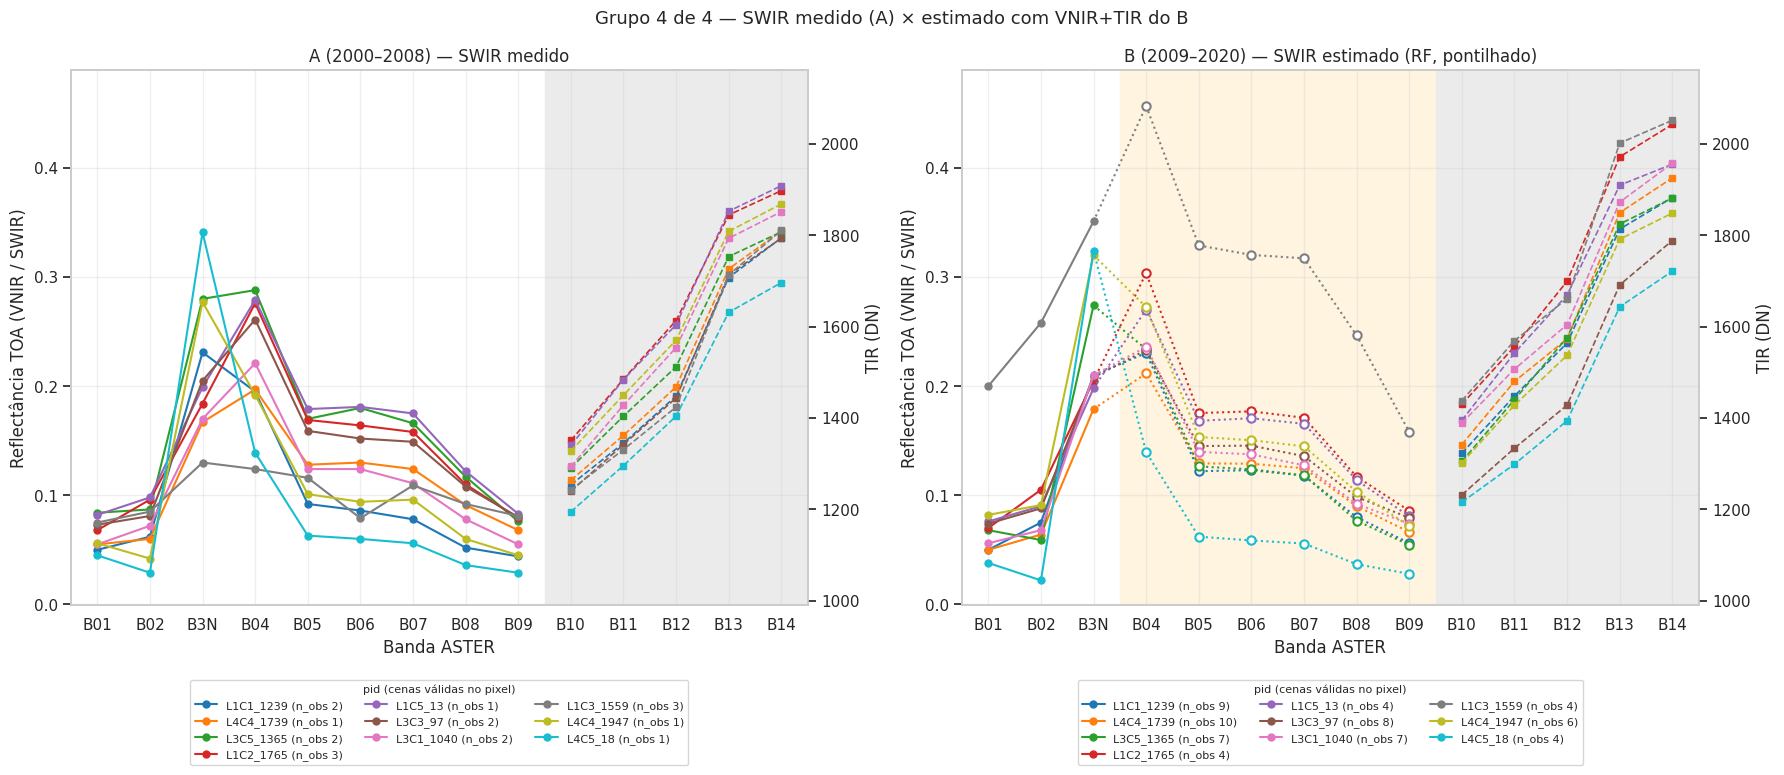

In [27]:
# [Célula 21A]
# Mesmos pontos/grupos da Célula 12A (df_pts, N_GRUPOS, N_PONTOS, cores_pts).
# Direita: VNIR + TIR medidos no B e o SWIR ESTIMADO por MODELO_EST a partir deles
# (pontilhado, marcador vazio). Esquerda: SWIR medido no A, para comparar.
MODELO_EST = 'RF'      # 'PLS', 'XGBoost' ou 'RF'

modelos_est = {'PLS': pls_models, 'XGBoost': xgb_models, 'RF': rf_models}[MODELO_EST]
X_est = scaler.transform(df_pts[[f'{b}_B' for b in FEATURES]].values.astype('float32'))
df_est = df_pts.copy()
for b in SWIR:
    df_est[f'{b}_est_B'] = np.asarray(modelos_est[b].predict(X_est)).ravel()

lim_t = limites([b + s for s in ('_A', '_B') for b in TIR])


def limites_est(colunas, folga=0.05):
    v = df_est[colunas].to_numpy()
    lo, hi = np.nanmin(v), np.nanmax(v)
    return lo - folga * (hi - lo), hi + folga * (hi - lo)

lim_r = limites_est([b + '_A' for b in VNIR + SWIR] + [b + '_B' for b in VNIR]
                    + [f'{b}_est_B' for b in SWIR])


def plot_grupo_est(grupo, g):
    fig, axes = plt.subplots(1, 2, figsize=(18, 8))
    for ax, suf in zip(axes, ('_A', '_B')):
        ax_t = ax.twinx()
        for cor, (_, p) in zip(cores_pts, grupo.iterrows()):
            rot = f'{p["pid"]} (n_obs {int(p["n_obs" + suf])})'
            if suf == '_A':
                ax.plot([POS[b] for b in VNIR + SWIR], [p[b + suf] for b in VNIR + SWIR],
                        'o-', color=cor, lw=1.5, ms=5, label=rot)
            else:
                ax.plot([POS[b] for b in VNIR], [p[b + suf] for b in VNIR],
                        'o-', color=cor, lw=1.5, ms=5, label=rot)
                # SWIR estimado, ligado à B3N medida
                xs = [POS['B3N']] + [POS[b] for b in SWIR]
                ys = [p['B3N' + suf]] + [p[f'{b}_est_B'] for b in SWIR]
                ax.plot(xs, ys, ':', color=cor, lw=1.5)
                ax.plot(xs[1:], ys[1:], 'o', mfc='white', mec=cor, mew=1.5, ms=6, ls='none')
            ax_t.plot([POS[b] for b in TIR], [p[b + suf] for b in TIR], 's--', color=cor, lw=1.2, ms=4)
        ax.axvspan(POS['B04'] - 0.5, POS['B09'] + 0.5, color='#fff4e0' if suf == '_B' else 'white', zorder=0)
        ax.axvspan(POS['B10'] - 0.5, POS['B14'] + 0.5, color='0.92', zorder=0)
        ax.set_xticks(range(len(ORDEM)), ORDEM)
        ax.set_xlim(-0.5, len(ORDEM) - 0.5)
        ax.set_ylim(lim_r)
        ax_t.set_ylim(lim_t)
        ax.set_title('A (2000–2008) — SWIR medido' if suf == '_A'
                     else f'B (2009–2020) — SWIR estimado ({MODELO_EST}, pontilhado)', fontsize=12)
        ax.set_xlabel('Banda ASTER')
        ax.set_ylabel(f'{ROTULO_REFL} (VNIR / SWIR)')
        ax_t.set_ylabel('TIR (DN)')
        ax.grid(alpha=0.3)
        ax_t.grid(False)
        ax.legend(fontsize=8, title='pid (cenas válidas no pixel)', title_fontsize=8, ncol=3,
                  loc='upper center', bbox_to_anchor=(0.5, -0.13))
    plt.suptitle(f'Grupo {g} de {N_GRUPOS} — SWIR medido (A) × estimado com VNIR+TIR do B',
                 fontsize=13)
    plt.tight_layout()
    salvar(plt.gcf(), '21A', f'assinaturas_swir_estimado_{MODELO_EST}_grupo{g}')
    plt.show()


for g in range(N_GRUPOS):
    plot_grupo_est(df_est.iloc[g * N_PONTOS:(g + 1) * N_PONTOS], g + 1)

## 7. Salvar Modelos e Artefatos

In [28]:
# [Célula 22]
# Scaler
joblib.dump(scaler, MODELS_DIR / 'scaler.joblib')

# Modelos por banda
for banda in TARGETS:
    joblib.dump(pls_models[banda], MODELS_DIR / f'pls_{banda}.joblib')
    joblib.dump(xgb_models[banda], MODELS_DIR / f'xgb_{banda}.joblib')
    joblib.dump(rf_models[banda],  MODELS_DIR / f'rf_{banda}.joblib')

# Parâmetros
best_params_out = {'pls': pls_params, 'xgb': xgb_params, 'rf': rf_params}
with open(MODELS_DIR / 'best_params.json', 'w') as f:
    json.dump(best_params_out, f, indent=2, default=str)

# Métricas
metrics_out = {mod.lower(): {b: v for b, v in vals.items()}
               for mod, vals in all_metrics.items()}
with open(MODELS_DIR / 'metrics.json', 'w') as f:
    json.dump(metrics_out, f, indent=2)

print('Arquivos salvos em', MODELS_DIR.resolve())
for f in sorted(MODELS_DIR.iterdir()):
    print(f'  {f.name}')

Arquivos salvos em /home/superuser/Dados/proj/prosprectra/modelagem_prospectra_mine/src/modeling/models/sazonal_seco_hm_razao
  best_params.json
  figuras
  metrics.json
  pls_B04.joblib
  pls_B05.joblib
  pls_B06.joblib
  pls_B07.joblib
  pls_B08.joblib
  pls_B09.joblib
  rf_B04.joblib
  rf_B05.joblib
  rf_B06.joblib
  rf_B07.joblib
  rf_B08.joblib
  rf_B09.joblib
  scaler.joblib
  xgb_B04.joblib
  xgb_B05.joblib
  xgb_B06.joblib
  xgb_B07.joblib
  xgb_B08.joblib
  xgb_B09.joblib


## 8. Teste temporal nos pontos pareados

Nos mesmos pontos, os modelos (treinados só com o A) recebem o VNIR+TIR do **B** e o SWIR
estimado é comparado com o SWIR **medido no A**. O erro junta o erro do modelo, a diferença
radiométrica entre os mosaicos (anos, cenas, temperatura) e a mudança real da superfície — é um
limite superior do erro na aplicação. A coluna `ref_A` repete a comparação com o VNIR+TIR do A
(mesmo dado do treino, otimista).

As estimativas do melhor modelo nos pontos do B vão para `points_sazonal_seco_B_swir_est.csv`.

In [29]:
# [Célula 23]
df_par = pd.read_csv(CSV_PAREADOS)
if CELULAS:
    df_par = df_par[df_par['celula_nome'].isin(CELULAS)]
df_par = df_par[(df_par['n_obs_A'] >= N_OBS_MIN) & (df_par['n_obs_B'] >= N_OBS_MIN)]
df_par = escalar(escalar(df_par, '_A'), '_B')
f_B   = [f'{b}_B' for b in FEATURES]
f_A   = [f'{b}_A' for b in FEATURES]
alvos = [f'{b}_A' for b in TARGETS]
ruins = (df_par[f_B + f_A + alvos] <= 0).any(axis=1)
df_par = df_par[~ruins].dropna(subset=f_B + f_A + alvos).reset_index(drop=True)
print(f'Pontos pareados: {len(df_par):,} em {df_par["celula_nome"].nunique()} células '
      f'({ruins.sum():,} com banda <= 0 removidos)')

Xp_B = scaler.transform(df_par[f_B].values.astype('float32'))
Xp_A = scaler.transform(df_par[f_A].values.astype('float32'))
Yp   = df_par[alvos].values

modelos_todos = {'PLS': pls_models, 'XGBoost': xgb_models, 'RF': rf_models}

def prever(modelos, X):
    return {b: np.asarray(modelos[b].predict(X)).ravel() for b in TARGETS}

temporal = {}
for mod, modelos in modelos_todos.items():
    p_B, p_A = prever(modelos, Xp_B), prever(modelos, Xp_A)
    for j, b in enumerate(TARGETS):
        m, r = avaliar(Yp[:, j], p_B[b]), avaliar(Yp[:, j], p_A[b])
        temporal[(mod, b)] = {'r2_B': m['r2'], 'rmse_B': m['rmse'],
                              'r2_ref_A': r['r2'], 'rmse_ref_A': r['rmse']}

df_temporal = pd.DataFrame(temporal).T
df_temporal.index.names = ['Modelo', 'Banda']
display(df_temporal.round(4).style
    .background_gradient(cmap='RdYlGn', subset=['r2_B', 'r2_ref_A'], vmin=0, vmax=1)
    .set_caption('Teste temporal — SWIR medido no A vs estimado'))

Pontos pareados: 49,931 em 25 células (34 com banda <= 0 removidos)


R² médio (B): {'PLS': 0.3009, 'RF': 0.3622, 'XGBoost': 0.3643} → melhor: XGBoost
figura → models/sazonal_seco_hm_razao/figuras/c24_teste_temporal_XGBoost.png


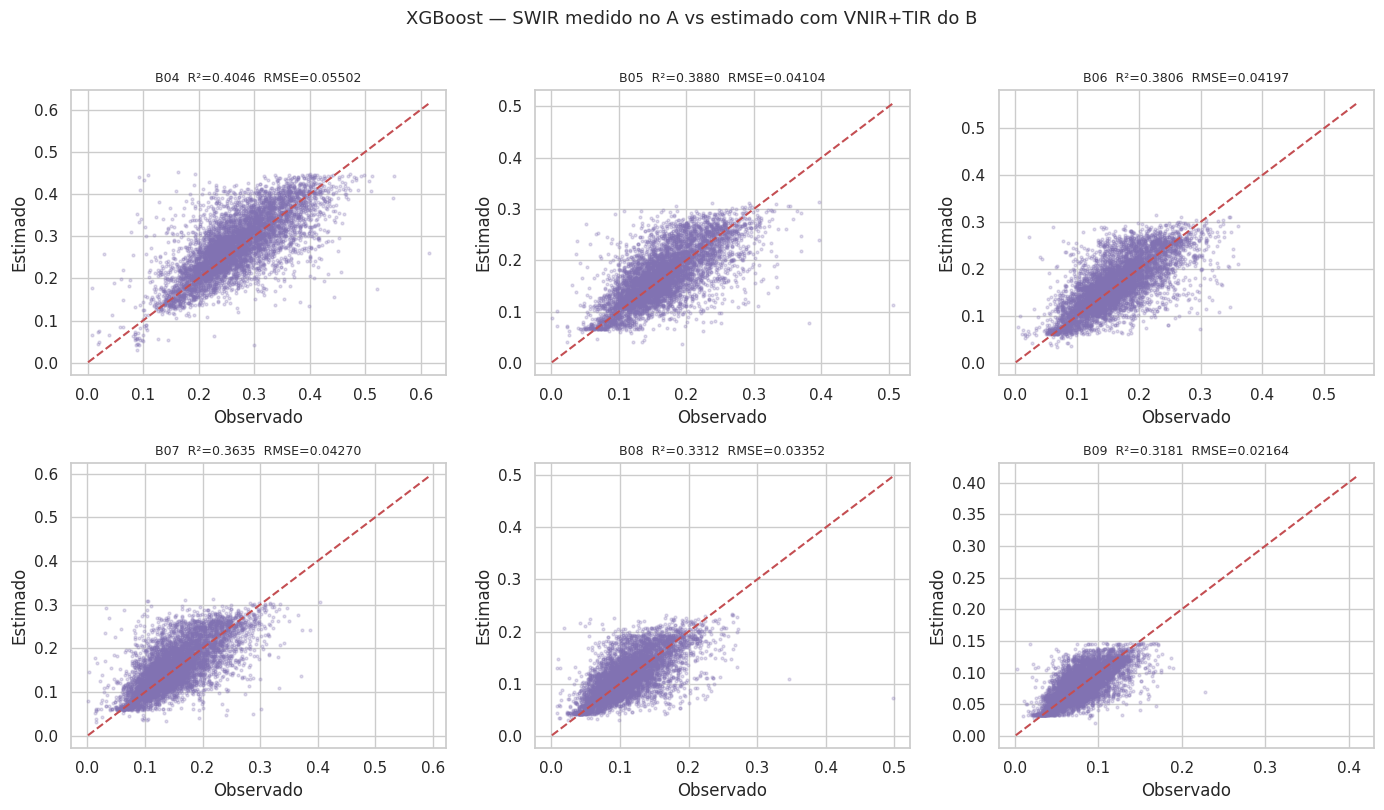

49,931 pontos -> /home/superuser/Dados/proj/prosprectra/modelagem_prospectra_mine/src/Dados/ASTER_Samples_sazonal_seco_hm_razao/points_sazonal_seco_B_swir_est.csv  (reflectância 0–1; TIR em DN)


In [30]:
# [Célula 24]
# Melhor modelo = maior R² médio no teste temporal
r2_medio = df_temporal['r2_B'].groupby(level='Modelo').mean()
melhor_mod = r2_medio.idxmax()
print('R² médio (B):', r2_medio.round(4).to_dict(), '→ melhor:', melhor_mod)

p_melhor = prever(modelos_todos[melhor_mod], Xp_B)
plot_scatter(p_melhor, Yp, f'{melhor_mod} — SWIR medido no A vs estimado com VNIR+TIR do B', '#8172B2',
             celula='24', nome=f'teste_temporal_{melhor_mod}')

saida = df_par[['pid', 'celula_id', 'celula_nome', 'longitude', 'latitude'] + f_B + alvos].copy()
for b in TARGETS:
    saida[f'{b}_est'] = p_melhor[b]
saida['modelo'] = melhor_mod
arq_est = CSV_DIR / 'points_sazonal_seco_B_swir_est.csv'
saida.to_csv(arq_est, index=False)
df_temporal.to_csv(MODELS_DIR / 'teste_temporal.csv')
print(f'{len(saida):,} pontos -> {arq_est}  (reflectância 0–1; TIR em DN)')

## 9. Treino direto nos pares (VNIR + TIR do B → SWIR do A)

O modelo da seção 8 aprende A → A e é aplicado ao B: a diferença radiométrica B × A (outros
anos e cenas, temperatura do TIR, envelhecimento do sensor) não aparece no treino. Aqui o
modelo recebe as features **do B** e o alvo é o SWIR **do A** no mesmo ponto — aprende a
diferença junto. É o grupo `sazonal_pareado` do `estimar_swir_rf_v2.py`, que lê os
hiperparâmetros salvos aqui (`best_params_pareado.json`).

**9.1 Teto.** A própria banda medida no B como "previsão" da mesma banda no A (sem modelo):
mostra quanto as duas datas concordam.

**9.2 Treino pareado.** RF com `RandomizedSearchCV` nos pares (mesmo espaço de busca da seção 5)
e XGBoost com os hiperparâmetros da seção 4. Duas validações:
- `aleat` — mesmo split 80/20 aleatório, comparando com o modelo A da seção 8 nos mesmos pontos
  (otimista: pontos vizinhos são parecidos);
- `celula_fora` — `GroupKFold` por célula: a célula testada nunca entra no treino (honesto).

Ressalva: o modelo A foi treinado com o SWIR do A nesses mesmos `pid`, então a coluna
`r2_modeloA_*` também é otimista.

In [31]:
# [Célula 25]
# ── 9.1 Teto: a banda medida no B como "previsão" da mesma banda no A ──────
linhas = []
for b in FEATURES:
    a, c = df_par[f'{b}_A'].values, df_par[f'{b}_B'].values
    linhas.append({'Banda': b, 'r2': avaliar(a, c)['r2'], 'rmse': avaliar(a, c)['rmse'],
                   'corr': float(np.corrcoef(a, c)[0, 1]), 'razao_media_B_A': c.mean() / a.mean(),
                   'razao_dp_B_A': c.std() / a.std()})
df_teto = pd.DataFrame(linhas).set_index('Banda')
display(df_teto.round(3).style
    .background_gradient(cmap='RdYlGn', subset=['r2', 'corr'], vmin=-1, vmax=1)
    .set_caption('Teto — banda medida no B × no A (mesmo ponto)'))
df_teto.to_csv(MODELS_DIR / 'teto_bandas_B_vs_A.csv')

,r2,rmse,corr,razao_media_B_A,razao_dp_B_A
Banda,,,,,
B01,0.143000,0.024000,0.580000,0.970000,1.009000
B02,0.270000,0.032000,0.674000,1.013000,1.103000
B3N,0.159000,0.046000,0.663000,1.080000,1.059000
B10,0.086000,84.767000,0.697000,1.038000,0.985000
B11,0.233000,90.506000,0.723000,1.034000,0.973000
B12,0.301000,93.992000,0.725000,1.030000,0.966000
B13,0.236000,100.280000,0.733000,1.031000,0.991000
B14,0.109000,103.885000,0.711000,1.033000,1.000000


B04  RF pareado GEE: {'numberOfTrees': 141, 'variablesPerSplit': 3, 'minLeafPopulation': 6, 'bagFraction': 0.878, 'maxNodes': 4096}
B05  RF pareado GEE: {'numberOfTrees': 141, 'variablesPerSplit': 3, 'minLeafPopulation': 6, 'bagFraction': 0.878, 'maxNodes': 4096}
B06  RF pareado GEE: {'numberOfTrees': 143, 'variablesPerSplit': 3, 'minLeafPopulation': 7, 'bagFraction': 0.615, 'maxNodes': None}
B07  RF pareado GEE: {'numberOfTrees': 141, 'variablesPerSplit': 3, 'minLeafPopulation': 6, 'bagFraction': 0.878, 'maxNodes': 4096}
B08  RF pareado GEE: {'numberOfTrees': 141, 'variablesPerSplit': 3, 'minLeafPopulation': 6, 'bagFraction': 0.878, 'maxNodes': 4096}
B09  RF pareado GEE: {'numberOfTrees': 141, 'variablesPerSplit': 3, 'minLeafPopulation': 6, 'bagFraction': 0.878, 'maxNodes': 4096}
RF pareado validado (5 folds por célula)
XGBoost pareado validado (5 folds por célula)


R² médio:
Modelo                       RF  XGBoost
r2_modeloA_aleat          0.375    0.372
r2_pareado_aleat          0.543    0.522
r2_modeloA_todos          0.362    0.364
r2_pareado_celula_fora    0.489    0.483
rmse_pareado_celula_fora  0.035    0.035
figura → models/sazonal_seco_hm_razao/figuras/c26_pareado_rf_celula_fora.png


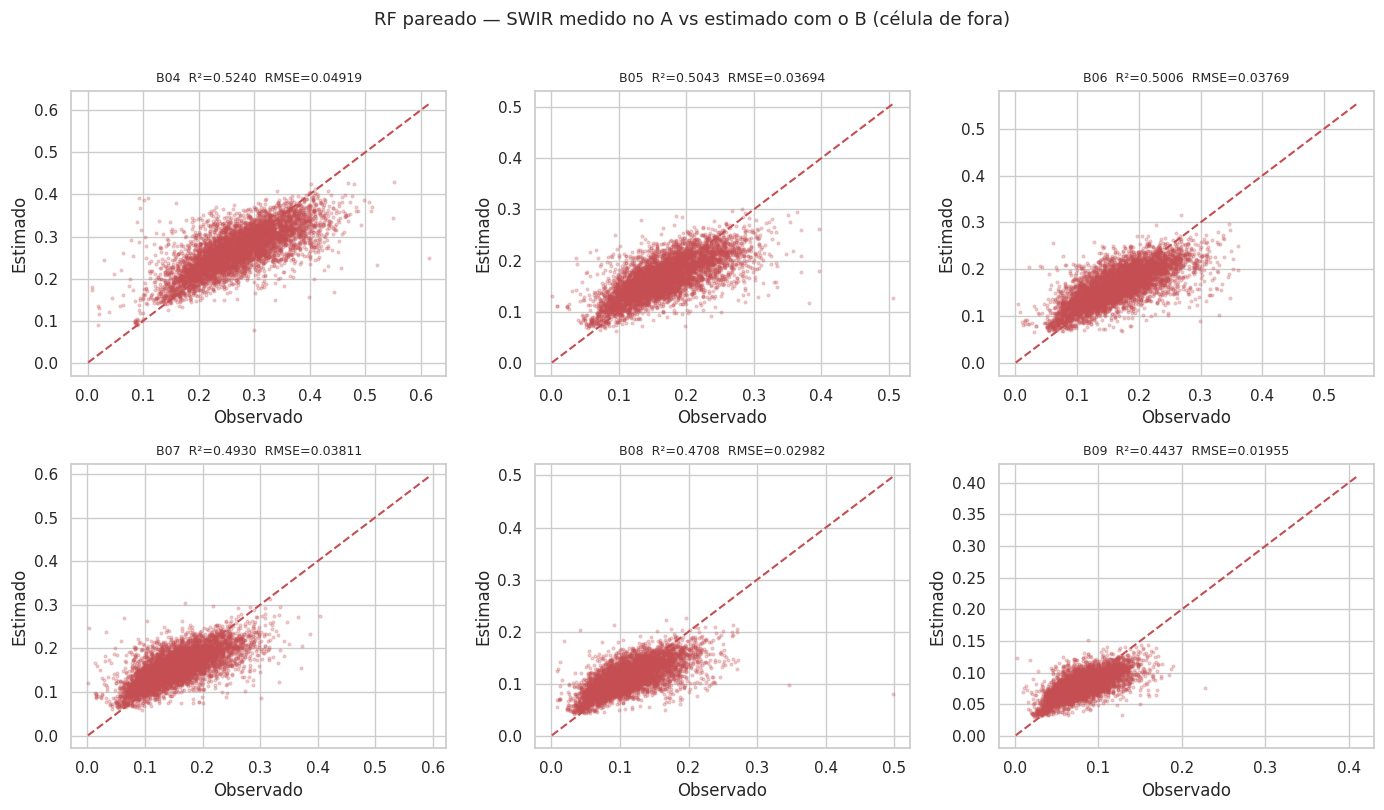

In [32]:
# [Célula 26]
# ── 9.2 Treino pareado: features do B, alvo SWIR do A ─────────────────────
from sklearn.base import clone
from sklearn.model_selection import GroupKFold

Xb  = df_par[f_B].values.astype('float32')
cel = df_par['celula_nome'].to_numpy()
idx_tr, idx_te = train_test_split(np.arange(len(df_par)), test_size=0.2, random_state=SEED)
scaler_par = StandardScaler().fit(Xb[idx_tr])
Xb_s = scaler_par.transform(Xb)

par_models, par_params = {'RF': {}, 'XGBoost': {}}, {}
for j, b in enumerate(TARGETS):
    search = RandomizedSearchCV(
        RandomForestRegressor(bootstrap=True, random_state=SEED, n_jobs=1), RF_PARAM_DIST,
        n_iter=N_ITER_RF, cv=kf, scoring='neg_root_mean_squared_error',
        random_state=SEED, n_jobs=N_JOBS, refit=True, verbose=0)
    search.fit(Xb_s[idx_tr], Yp[idx_tr, j])
    par_models['RF'][b] = search.best_estimator_
    p = search.best_params_
    par_params[b] = {**p, 'cv_rmse': float(-search.best_score_),
                     'gee': {'numberOfTrees': int(p['n_estimators']),
                             'variablesPerSplit': int(p['max_features']),
                             'minLeafPopulation': int(p['min_samples_leaf']),
                             'bagFraction': round(float(p['max_samples']), 3),
                             'maxNodes': p['max_leaf_nodes']}}
    par_models['XGBoost'][b] = clone(xgb_models[b]).fit(Xb_s[idx_tr], Yp[idx_tr, j])
    print(f'{b}  RF pareado GEE: {par_params[b]["gee"]}')

gkf = GroupKFold(n_splits=min(5, len(np.unique(cel))))
par_oof, linhas = {'RF': {}, 'XGBoost': {}}, []
for mod in ('RF', 'XGBoost'):
    modelos_A = {'RF': rf_models, 'XGBoost': xgb_models}[mod]
    for j, b in enumerate(TARGETS):
        oof = np.full(len(df_par), np.nan)
        for tr, te in gkf.split(Xb, groups=cel):
            sc = StandardScaler().fit(Xb[tr])
            oof[te] = clone(par_models[mod][b]).fit(sc.transform(Xb[tr]), Yp[tr, j]).predict(sc.transform(Xb[te]))
        par_oof[mod][b] = oof
        p_A = np.asarray(modelos_A[b].predict(Xp_B)).ravel()
        linhas.append({
            'Modelo': mod, 'Banda': b,
            'r2_modeloA_aleat':       avaliar(Yp[idx_te, j], p_A[idx_te])['r2'],
            'r2_pareado_aleat':       avaliar(Yp[idx_te, j], par_models[mod][b].predict(Xb_s[idx_te]))['r2'],
            'r2_modeloA_todos':       avaliar(Yp[:, j], p_A)['r2'],
            'r2_pareado_celula_fora': avaliar(Yp[:, j], oof)['r2'],
            'rmse_pareado_celula_fora': avaliar(Yp[:, j], oof)['rmse'],
        })
    print(f'{mod} pareado validado ({gkf.get_n_splits()} folds por célula)')

df_par_val = pd.DataFrame(linhas).set_index(['Modelo', 'Banda'])
cols_r2 = [c for c in df_par_val.columns if c.startswith('r2')]
display(df_par_val.round(3).style
    .background_gradient(cmap='RdYlGn', subset=cols_r2, vmin=-1, vmax=1)
    .set_caption('Modelo A (seção 8) × modelo pareado (R²)'))
print('R² médio:')
print(df_par_val.groupby(level='Modelo').mean().round(3).T.to_string())
df_par_val.to_csv(MODELS_DIR / 'teste_pareado.csv')

plot_scatter(par_oof['RF'], Yp, 'RF pareado — SWIR medido no A vs estimado com o B (célula de fora)',
             '#C44E52', celula='26', nome='pareado_rf_celula_fora')

In [33]:
# [Célula 26A]
# ── Salvar o modelo pareado (lido pelo estimar_swir_rf_v2.py, grupo sazonal_pareado) ─
joblib.dump(scaler_par, MODELS_DIR / 'scaler_pareado.joblib')
for b in TARGETS:
    joblib.dump(par_models['RF'][b],      MODELS_DIR / f'rf_pareado_{b}.joblib')
    joblib.dump(par_models['XGBoost'][b], MODELS_DIR / f'xgb_pareado_{b}.joblib')
with open(MODELS_DIR / 'best_params_pareado.json', 'w') as f:
    json.dump({'rf': par_params}, f, indent=2, default=str)
print('→', (MODELS_DIR / 'best_params_pareado.json').resolve())

→ /home/superuser/Dados/proj/prosprectra/modelagem_prospectra_mine/src/modeling/models/sazonal_seco_hm_razao/best_params_pareado.json


## 10. Normalização radiométrica B → A

Antes de aplicar o modelo da seção 5 (treinado no A), leva o VNIR+TIR do B para as condições
do A, banda a banda, usando os pontos pareados (mesmo lugar, dois períodos).

| Eixo | Opções | Por quê |
|---|---|---|
| Método | `ols` (reta comum), `rma` (eixo maior reduzido), `qm` (quantile mapping) | com correlação baixa entre os períodos, a reta comum tem inclinação ≈ corr × σA/σB e **achata** a imagem para a média; `rma` e `qm` preservam a variância |
| Agrupamento | `global`, `celula` | sem banda `data` não há reta por cena; a célula é a unidade do `estimar_swir_rf_v2.py` (célula com menos de `MIN_GRUPO` pontos de treino usa a global) |
| Pontos | todos, ou só **estáveis** (\|ΔNDVI\| ≤ `LIM_DNDVI`) | mudança real da superfície (cultivo, vegetação) não deve entrar na transformação |

Validação fora da amostra: `global` — uma célula de fora por vez (ajuste nas outras);
`celula` — `KFold(5)` dentro da célula (a reta é da própria célula, como no GEE).

Métricas: concordância das bandas normalizadas com as do A (R² e razão de desvio padrão — perto
de 1 = contraste preservado) e R² do SWIR estimado (RF e XGBoost das seções 4–5). A última linha
lembra o R² do modelo pareado (seção 9, célula de fora) para comparar.

O `estimar_swir_rf_v2.py` (grupo `sazonal_seco`) só tem `ols` (`global` ou `celula`).

In [34]:
# [Célula 27]
# ── 10.1–10.4 Normalização por banda: métodos × agrupamento × pontos estáveis ─
import itertools, time

METODOS   = ['ols', 'rma', 'qm']
AGRUPAR   = ['global', 'celula']
ESTAVEIS  = [False, True]
MIN_GRUPO = 200      # pontos de treino mínimos para a célula ter reta própria
LIM_DNDVI = 0.05     # ponto estável: |NDVI do B − NDVI do A| ≤ LIM_DNDVI

xB = df_par[f_B].to_numpy(float)
yA = df_par[f_A].to_numpy(float)
celula = df_par['celula_nome'].to_numpy()

def ndvi(df, suf):
    n, r = df[f'B3N{suf}'], df[f'B02{suf}']
    return ((n - r) / (n + r)).to_numpy()

dndvi   = np.abs(ndvi(df_par, '_B') - ndvi(df_par, '_A'))
estavel = dndvi <= LIM_DNDVI
print(f'Pontos estáveis (|ΔNDVI| ≤ {LIM_DNDVI}): {estavel.sum():,} de {len(estavel):,} ({estavel.mean():.0%})')


def ajustar(metodo, x, y):
    """Função x(B) → y(escala do A) para uma banda."""
    if metodo == 'ols':
        b, a = np.polyfit(x, y, 1)
        return lambda z: a + b * z
    if metodo == 'rma':
        r = np.corrcoef(x, y)[0, 1]
        b = np.sign(r) * y.std() / x.std()
        a = y.mean() - b * x.mean()
        return lambda z: a + b * z
    q = np.linspace(0, 1, 101)
    qx, qy = np.quantile(x, q), np.quantile(y, q)
    return lambda z: np.interp(z, qx, qy)


def normalizar(metodo, agrupar, so_estaveis):
    """Bandas do B normalizadas, fora da amostra."""
    out = np.full_like(xB, np.nan)
    ok = estavel if so_estaveis else np.ones(len(xB), bool)
    for cel_ in np.unique(celula):
        te = celula == cel_
        idx = np.flatnonzero(te)
        for j in range(xB.shape[1]):
            fora = ~te & ok
            f_glob = ajustar(metodo, xB[fora, j], yA[fora, j])
            if agrupar == 'global' or len(idx) < 5:
                out[te, j] = f_glob(xB[te, j])
                continue
            for tr, tt in KFold(5, shuffle=True, random_state=SEED).split(idx):
                s_tr = idx[tr][ok[idx[tr]]]
                f = ajustar(metodo, xB[s_tr, j], yA[s_tr, j]) if len(s_tr) >= MIN_GRUPO else f_glob
                out[idx[tt], j] = f(xB[idx[tt], j])
    return out


def metricas(xn):
    lin = {}
    r2b = [avaliar(yA[:, j], xn[:, j])['r2'] for j in range(len(FEATURES))]
    sdr = [xn[:, j].std() / yA[:, j].std() for j in range(len(FEATURES))]
    lin['r2_bandas_vnir'] = np.mean(r2b[:3]);  lin['r2_bandas_tir'] = np.mean(r2b[3:])
    lin['razao_dp_vnir']  = np.mean(sdr[:3]);  lin['razao_dp_tir']  = np.mean(sdr[3:])
    Xs = scaler.transform(xn.astype('float32'))
    for mod, modelos in (('RF', rf_models), ('XGBoost', xgb_models)):
        p = prever(modelos, Xs)
        lin[f'{mod}_swir'] = np.mean([avaliar(Yp[:, j], p[b])['r2'] for j, b in enumerate(TARGETS)])
    return lin


t0 = time.time()
linhas = [{'metodo': 'nenhuma', 'agrupar': '-', 'estaveis': '-', **metricas(xB)}]
normalizados = {}
for metodo, agrupar, so_est in itertools.product(METODOS, AGRUPAR, ESTAVEIS):
    xn = normalizar(metodo, agrupar, so_est)
    normalizados[(metodo, agrupar, so_est)] = xn
    linhas.append({'metodo': metodo, 'agrupar': agrupar, 'estaveis': so_est, **metricas(xn)})
print(f'{len(linhas) - 1} configurações em {time.time() - t0:.0f} s')

df_norm = (pd.DataFrame(linhas).set_index(['metodo', 'agrupar', 'estaveis'])
             .sort_values('RF_swir', ascending=False))
cols_r2 = [c for c in df_norm.columns if 'r2' in c or 'swir' in c]
display(df_norm.round(3).style
    .background_gradient(cmap='RdYlGn', subset=cols_r2, vmin=-1, vmax=1)
    .background_gradient(cmap='coolwarm_r', subset=['razao_dp_vnir', 'razao_dp_tir'], vmin=0, vmax=2)
    .set_caption('Normalização B → A (fora da amostra)'))
df_norm.to_csv(MODELS_DIR / 'normalizacao_radiometrica.csv')
print('Comparar com o modelo pareado (seção 9, célula de fora), R² médio do SWIR:',
      {m: round(float(np.mean([avaliar(Yp[:, j], par_oof[m][b])['r2'] for j, b in enumerate(TARGETS)])), 3)
       for m in par_oof})

Pontos estáveis (|ΔNDVI| ≤ 0.05): 22,873 de 49,931 (46%)
12 configurações em 82 s


Comparar com o modelo pareado (seção 9, célula de fora), R² médio do SWIR: {'RF': 0.489, 'XGBoost': 0.483}


In [ ]:
# [Célula 28]
# ── 10.5 Assinaturas: SWIR medido × estimado sem/com normalização × pareado ──
# Melhor configuração que preserva o contraste (razão de desvio padrão ≥ 0,7)
cand = df_norm.drop(index=('nenhuma', '-', '-'))
cand = cand[(cand['razao_dp_vnir'] >= 0.7) & (cand['razao_dp_tir'] >= 0.7)]
melhor_cfg = cand['RF_swir'].idxmax()
print('Melhor configuração (contraste preservado):', melhor_cfg)
print(cand.loc[[melhor_cfg]].round(3).T.to_string())

xn_melhor = normalizados[melhor_cfg]
p_sem = prever(rf_models, scaler.transform(xB.astype('float32')))
p_com = prever(rf_models, scaler.transform(xn_melhor.astype('float32')))
p_par = par_oof['RF']
pos_pid = pd.Series(np.arange(len(df_par)), index=df_par['pid'])

refl = VNIR + SWIR
titulos = ['A — SWIR medido', 'B — modelo A SEM normalização',
           f'B — modelo A COM normalização {melhor_cfg[:2]}', 'B — modelo pareado (célula de fora)']
for g in range(N_GRUPOS):
    grupo = df_pts.iloc[g * N_PONTOS:(g + 1) * N_PONTOS]
    idx = pos_pid.reindex(grupo['pid']).dropna().astype(int).to_numpy()
    fig, axes = plt.subplots(1, 4, figsize=(26, 6.5), sharey=True)
    for k, (ax, titulo) in enumerate(zip(axes, titulos)):
        for cor, i in zip(cores_pts, idx):
            if k == 0:
                ys = [df_par[f'{b}_A'].iloc[i] for b in refl]
            else:
                vnir = xn_melhor[i, :3] if k == 2 else xB[i, :3]
                p = {1: p_sem, 2: p_com, 3: p_par}[k]
                ys = list(vnir) + [p[b][i] for b in SWIR]
            ax.plot(range(len(refl)), ys, 'o-' if k == 0 else 'o:', color=cor, lw=1.5, ms=5,
                    mfc=cor if k == 0 else 'white', label=df_par['pid'].iloc[i])
        ax.axvspan(2.5, len(refl) - 0.5, color='#fff4e0' if k else 'white', zorder=0)
        ax.set_xticks(range(len(refl)), refl)
        ax.set_title(titulo, fontsize=11)
        ax.set_xlabel('Banda ASTER')
        ax.grid(alpha=0.3)
    axes[0].set_ylabel(ROTULO_REFL)
    axes[0].legend(fontsize=7, ncol=2)
    plt.suptitle(f'Grupo {g + 1} de {N_GRUPOS} — SWIR estimado no B: normalização × treino pareado (RF)',
                 fontsize=13)
    plt.tight_layout()
    salvar(plt.gcf(), '28', f'normalizacao_pareado_assinaturas_grupo{g + 1}')
    plt.show()